# Détectez des faux billets

Objectif: Construire des algorithmes qui, à partir des caractéristiques géométriques d’un billet, serait capable de défi nir si ce dernier est un vrai ou un faux billet.

# 1) Chargement des bibliothèques et données

In [3]:
# Importer les bibliothèques nécessaires
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import statsmodels.api as sm
import shap
import joblib

from sklearn.linear_model import LinearRegression
#from sklearn.metrics import mean_squared_error, r2_score

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
#from sklearn.model_selection import train_test_split, GridSearchCV
#from sklearn.model_selection import train_test_split


from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve,
    ConfusionMatrixDisplay
)

In [4]:
os.listdir()

['Haraldsson_Matilda_1_notebook_042026.ipynb',
 'Haraldsson_Matilda_2_pipeline_regression_logistique_042026.ipynb',
 'Haraldsson_Matilda_3_presentation_042026.pdf']

In [2]:
# Telecharger les données
DATA_PATH = "billets.csv"

if not os.path.exists(DATA_PATH):
    print(f"❌ Attention : le fichier '{DATA_PATH}' n'existe pas.")

try:
    df = pd.read_csv(DATA_PATH, sep=";")
    print("✅ Données chargées :", df.shape)
    display(df.head())
except Exception as e:
    print("❌ Erreur lors du chargement :", e)


❌ Attention : le fichier 'billets.csv' n'existe pas.
❌ Erreur lors du chargement : [Errno 2] No such file or directory: 'billets.csv'


# 2) Analyse exploratoire (EDA)


# 2.1) Explore le données

In [66]:
# La variable `is_genuin` indique si un billet est authentique (valeur `True` dans 1 000 cas) ou frauduleux (valeur `False` dans 500 cas)
print("Nombre de billets authentiques (is_genuin = True):",(df["is_genuine"] == True).sum())
print("Nombre de billets frauduleux (is_genuin = False):",(df["is_genuine"] == False).sum())

print("\nLa variable `is_genuin` indique si un billet est authentique (valeur `True` dans 1 000 cas) ou frauduleux (valeur `False` dans 500 cas)\n")
print("⚠️ Attention: Comme l'objectif de ce etude est d'identifier les billets frauduleux, \ni.e., il s'agit de la classe que nous ciblerons avec nos modèles d'apprentissage automatique, \nnous allons donc transformer les données en données binaires ou: \n- 0 pour un billet authentique, et \n- 1 indique un billet frauduleux.\n")

df["is_Fake"] = (~df["is_genuine"]).astype(int)
df.head(3)

print("Control:")
print("Nombre de billets authentiques (is_Fake = 0):",(df["is_Fake"] == 0).sum())
print("Nombre de billets frauduleux (is_Fake = 1):",(df["is_Fake"] == 1).sum())


Nombre de billets authentiques (is_genuin = True): 1000
Nombre de billets frauduleux (is_genuin = False): 500

La variable `is_genuin` indique si un billet est authentique (valeur `True` dans 1 000 cas) ou frauduleux (valeur `False` dans 500 cas)

⚠️ Attention: Comme l'objectif de ce etude est d'identifier les billets frauduleux, 
i.e., il s'agit de la classe que nous ciblerons avec nos modèles d'apprentissage automatique, 
nous allons donc transformer les données en données binaires ou: 
- 0 pour un billet authentique, et 
- 1 indique un billet frauduleux.

Control:
Nombre de billets authentiques (is_Fake = 0): 1000
Nombre de billets frauduleux (is_Fake = 1): 500


In [67]:
# Afficher les types de données et le nombre de valeurs non nulles pour chaque colonne
print("Types de données :\n")
print(df.info())

print(f"\n⚠️ Attention : Column 'margin_low' a {df.shape[0] - (df['margin_low'].notnull().sum())} valeurs nulles.")

# Definier une variable avec les noms de columns ou les variables sont numériques
numerical_cols = ['diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up', 'length']


Types de données :

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   is_genuine    1500 non-null   bool   
 1   diagonal      1500 non-null   float64
 2   height_left   1500 non-null   float64
 3   height_right  1500 non-null   float64
 4   margin_low    1463 non-null   float64
 5   margin_up     1500 non-null   float64
 6   length        1500 non-null   float64
 7   is_Fake       1500 non-null   int32  
dtypes: bool(1), float64(6), int32(1)
memory usage: 77.8 KB
None

⚠️ Attention : Column 'margin_low' a 37 valeurs nulles.


In [68]:
# authentique
mask = df["is_Fake"] == 0
df_auth = df[mask]
df_auth.describe()


,diagonal,height_left,height_right,margin_low,margin_up,length,is_Fake
count,1000.000000,1000.000000,1000.00000,971.000000,1000.00000,1000.000000,1000.0
mean,171.987080,103.949130,103.80865,4.116097,3.05213,113.202430,0.0
std,0.300441,0.300231,0.29157,0.319124,0.18634,0.359552,0.0
min,171.040000,103.140000,102.82000,2.980000,2.27000,111.760000,0.0
25%,171.790000,103.740000,103.61000,3.905000,2.93000,112.950000,0.0
50%,171.990000,103.950000,103.81000,4.110000,3.05000,113.205000,0.0
75%,172.200000,104.140000,104.00000,4.340000,3.18000,113.460000,0.0
max,172.920000,104.860000,104.95000,5.040000,3.74000,114.440000,0.0


In [69]:
# fake
mask = df["is_Fake"] == 1
df_fake = df[mask]
df_fake.describe()

,diagonal,height_left,height_right,margin_low,margin_up,length,is_Fake
count,500.000000,500.000000,500.000000,492.000000,500.000000,500.000000,500.0
mean,171.901160,104.190340,104.143620,5.215935,3.350160,111.630640,1.0
std,0.306861,0.223758,0.270878,0.553531,0.180498,0.615543,0.0
min,171.040000,103.510000,103.430000,3.820000,2.920000,109.490000,1.0
25%,171.690000,104.040000,103.950000,4.840000,3.220000,111.200000,1.0
50%,171.910000,104.180000,104.160000,5.190000,3.350000,111.630000,1.0
75%,172.092500,104.332500,104.320000,5.592500,3.472500,112.030000,1.0
max,173.010000,104.880000,104.950000,6.900000,3.910000,113.850000,1.0


In [70]:
# Afficher les lignes ou 'margin_low' est null
print(f"Nombre de billets authentiques avec 'margin_low' null : {(df.loc[df['margin_low'].isnull(), 'is_Fake'] == 0).sum()}")
print(f"Nombre de billets falses avec 'margin_low' null : {(df.loc[df['margin_low'].isnull(), 'is_Fake'] == 1).sum()}")  

print("\nLignes avec 'margin_low' null :\n")
# df[df['margin_low'].isnull()]


Nombre de billets authentiques avec 'margin_low' null : 29
Nombre de billets falses avec 'margin_low' null : 8

Lignes avec 'margin_low' null :



In [71]:
# Verifier que'n a pas des ligne duplices
df.duplicated().sum()
if df.duplicated().sum() > 0:
    print(f"⚠️ Attention : il y a {df.duplicated().sum()} lignes dupliquées dans le dataset.")
else: 
    print("✅ Pas de lignes dupliquées dans le dataset.")


✅ Pas de lignes dupliquées dans le dataset.


Les variables ont une distributions symmetric (gaussian), et assez similaire entre les billets authentiques et les billets falses, 
ce qui rend la tâche de classification plus difficile. 
Cependant, on peut observer que certaines variables comme 'margin_low' et 'margin_high' ont des distributions légèrement différentes 
entre les deux classes, ce qui pourrait être utile pour la classification.


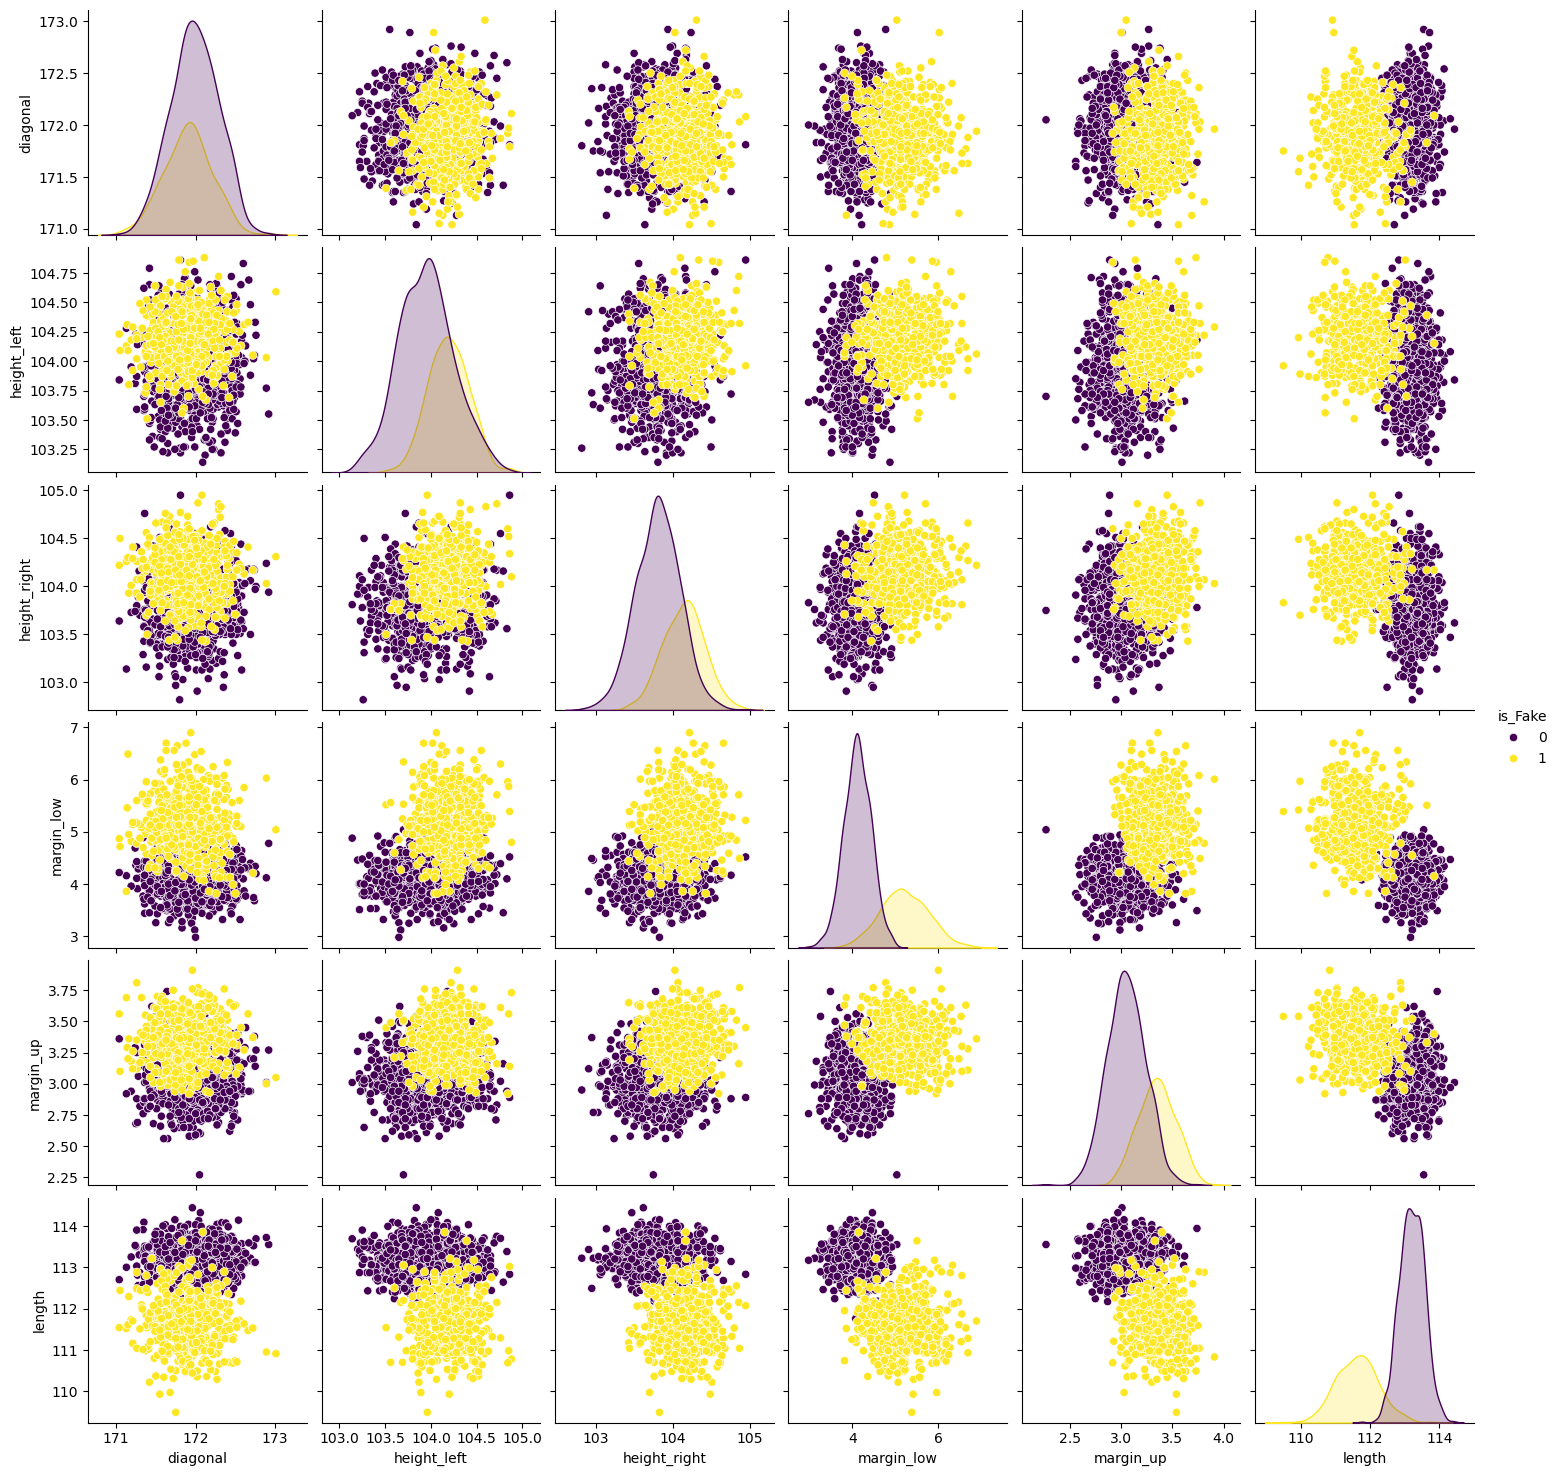

In [72]:
# Afficher le pairplot pour les variables numériques, en colorant les points selon la variable 'is_Fake'
# Pour visualiser les distribution pour chaque variable, et pour mieux visualiser les relations entre les variables
cmap = plt.get_cmap("viridis_r")
colors = [cmap(x) for x in np.linspace(1, 0, 2)]
colors
sns.pairplot(df.drop(columns=["is_genuine"]), hue="is_Fake", palette=colors)

print("Les variables ont une distributions symmetric (gaussian), et assez similaire entre les billets authentiques et les billets falses, \nce qui rend la tâche de classification plus difficile. \nCependant, on peut observer que certaines variables comme 'margin_low' et 'margin_high' ont des distributions légèrement différentes \nentre les deux classes, ce qui pourrait être utile pour la classification.")

👍 Le correlation motre que les variables 'margin_low' et 'length' sont fortement corrélées, et 'margin_low' et 'margin_up' modérément corrélé. 
Ces corrélations plus fortes avec margin_low indiquent que ces variables pourraient être utiles pour l'imputation.


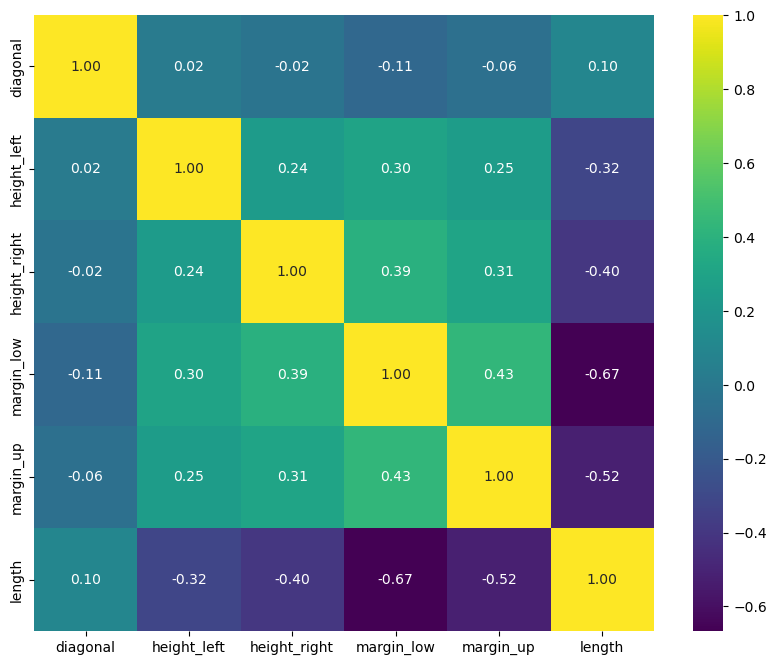

In [73]:
# Afficher les matriec de correlation pour les variables numeriques
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap="viridis", fmt=".2f")

print("👍 Le correlation motre que les variables 'margin_low' et 'length' sont fortement corrélées, et 'margin_low' et 'margin_up' modérément corrélé. \nCes corrélations plus fortes avec margin_low indiquent que ces variables pourraient être utiles pour l'imputation.")

# 2.2) L'imputation:

Le correlation motre que les variables 'margin_low' et 'length' sont fortement corrélées, et 'margin_low' et 'margin_up' modérément corrélé. \nCes corrélations plus fortes avec margin_low indiquent que ces variables pourraient être utiles pour l'imputation.

Je testerai donc trois modèles différents avant de choisir celui qui sera utilisé pour l'imputation.
 - Un modèle simple qui utilise seulement la variable 'length' pour prédire 'margin_low'.
 - Un modèle multiple qui utilise les variables 'length' et 'margin_up' pour prédire 'margin_low'.
 - Un modèle complet testant toutes les variables

Je les effectuerai par 
1) régression OLS classique, en comparant les modèles avec le R² et l'AIC, et ses diagnostique, et j'utiliserai également 
2) un modèle d'apprentissage automatique par division et entraînement pour vérifier la prédictibilité des modèles.

In [74]:
# Ordinary Least Squares Regression

# Garde que les lignes sans valeurs manquantes pour 'margin_low' 
df_sans_nan = df.dropna()

# Definier les variables predictors/indépendantes (X) 
regressions = {
    "simple: y ~ length" : ["length"],
    "multiple: y ~ length + margin_up" : ["length", "margin_up"],
    "full: y ~ length + margin_up + diagonal + height_left + height_right" : ["length","margin_up", "diagonal","height_left", "height_right"]
}

# Definier la variable target/dépendante (y)
y = df_sans_nan['margin_low']

# Boucle sur les régressions
for title, variables in regressions.items():

    X = df_sans_nan[variables]

    # Ajouter une constante pour le terme d'interception
    X = sm.add_constant(X)

    # Fit le modèle OLS
    model = sm.OLS(y, X).fit()

    # Afficher le résumé du modèle
    print(f"\n-- Regression {title}")
    print("model summary:\n", model.summary())



-- Regression simple: y ~ length
model summary:
                             OLS Regression Results                            
Dep. Variable:             margin_low   R-squared:                       0.445
Model:                            OLS   Adj. R-squared:                  0.444
Method:                 Least Squares   F-statistic:                     1169.
Date:                Wed, 20 May 2026   Prob (F-statistic):          8.98e-189
Time:                        23:51:43   Log-Likelihood:                -1045.8
No. Observations:                1463   AIC:                             2096.
Df Residuals:                    1461   BIC:                             2106.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
co


-- Regression simple: y ~ length
model summary:
                             OLS Regression Results                            
Dep. Variable:             margin_low   R-squared:                       0.445
Model:                            OLS   Adj. R-squared:                  0.444
Method:                 Least Squares   F-statistic:                     1169.
Date:                Wed, 20 May 2026   Prob (F-statistic):          8.98e-189
Time:                        23:51:43   Log-Likelihood:                -1045.8
No. Observations:                1463   AIC:                             2096.
Df Residuals:                    1461   BIC:                             2106.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
co

c:\Users\matil\anaconda3\envs\ML_basics\lib\site-packages\statsmodels\graphics\gofplots.py:1041: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b" (-> color=(0.0, 0.0, 1.0, 1)). The keyword argument will take precedence.
  ax.plot(x, y, fmt, **plot_style)


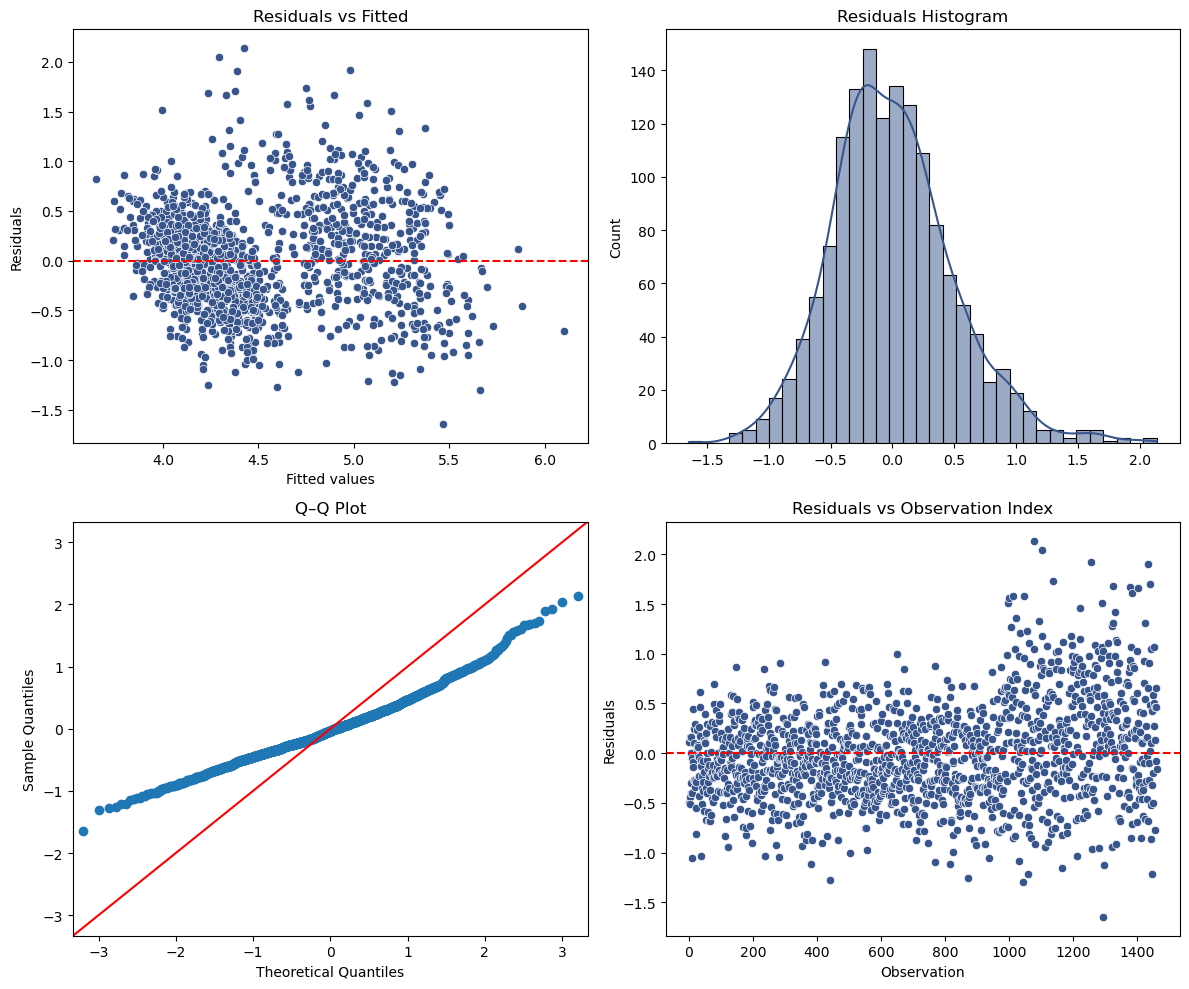


-- Regression multiple: y ~ length + margin_up
model summary:
                             OLS Regression Results                            
Dep. Variable:             margin_low   R-squared:                       0.454
Model:                            OLS   Adj. R-squared:                  0.454
Method:                 Least Squares   F-statistic:                     607.7
Date:                Wed, 20 May 2026   Prob (F-statistic):          9.76e-193
Time:                        23:51:44   Log-Likelihood:                -1032.9
No. Observations:                1463   AIC:                             2072.
Df Residuals:                    1460   BIC:                             2088.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------

c:\Users\matil\anaconda3\envs\ML_basics\lib\site-packages\statsmodels\graphics\gofplots.py:1041: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b" (-> color=(0.0, 0.0, 1.0, 1)). The keyword argument will take precedence.
  ax.plot(x, y, fmt, **plot_style)


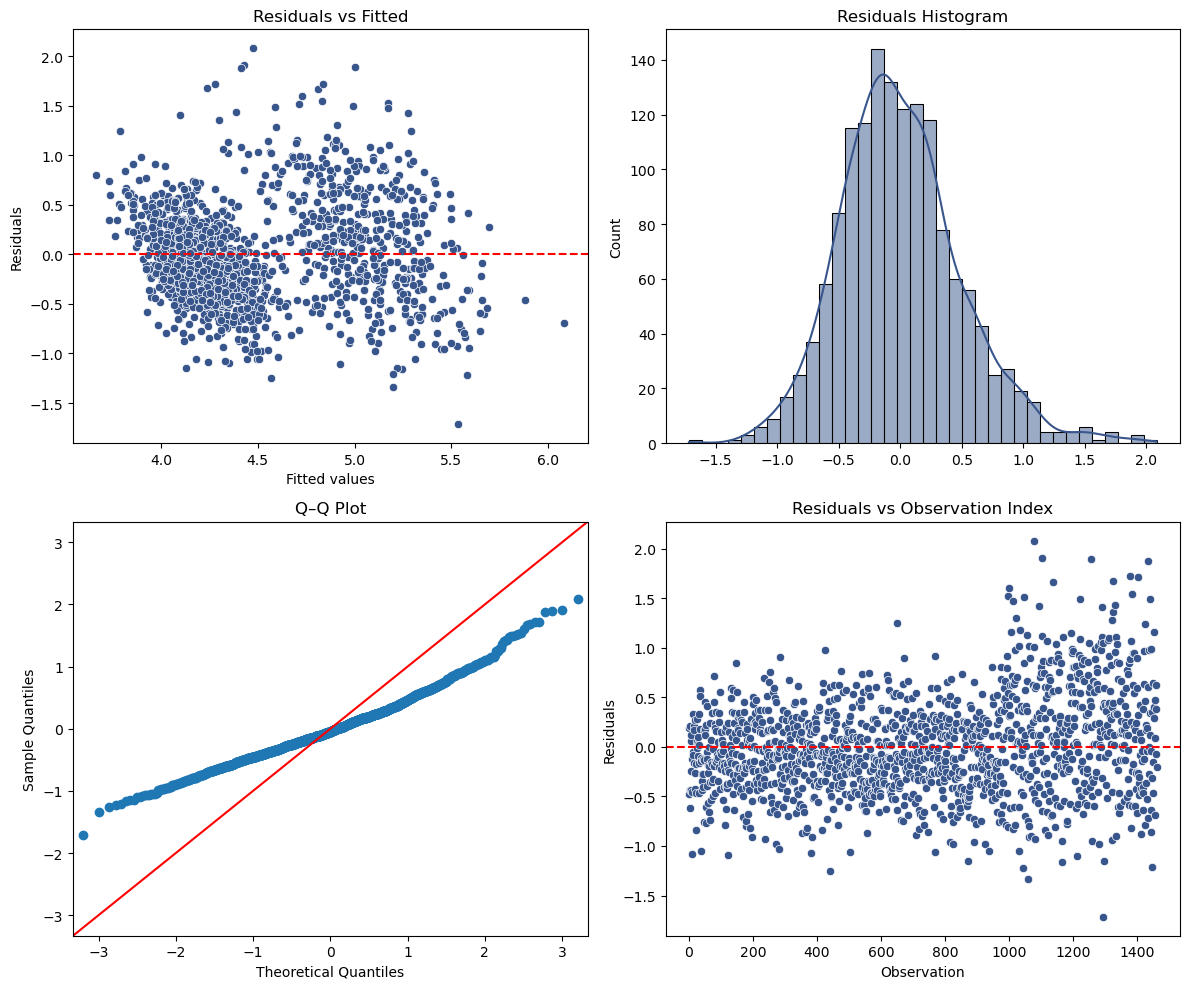


-- Regression full: y ~ length + margin_up + diagonal + height_left + height_right
model summary:
                             OLS Regression Results                            
Dep. Variable:             margin_low   R-squared:                       0.477
Model:                            OLS   Adj. R-squared:                  0.476
Method:                 Least Squares   F-statistic:                     266.1
Date:                Wed, 20 May 2026   Prob (F-statistic):          2.60e-202
Time:                        23:51:44   Log-Likelihood:                -1001.3
No. Observations:                1463   AIC:                             2015.
Df Residuals:                    1457   BIC:                             2046.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

c:\Users\matil\anaconda3\envs\ML_basics\lib\site-packages\statsmodels\graphics\gofplots.py:1041: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b" (-> color=(0.0, 0.0, 1.0, 1)). The keyword argument will take precedence.
  ax.plot(x, y, fmt, **plot_style)


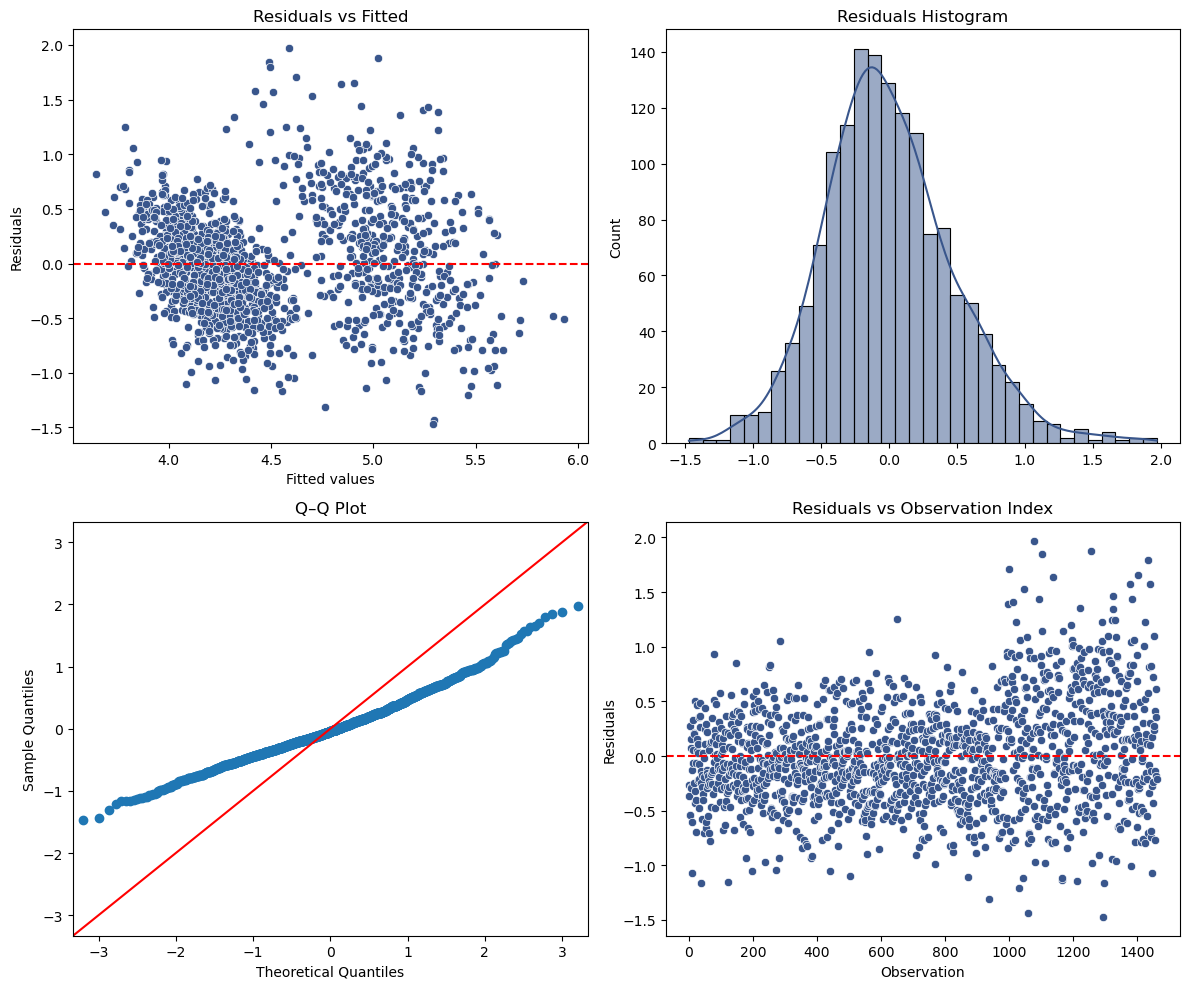

In [75]:
# Ordinary least square regression
df_sans_nan = df.dropna()

# Definier les variables predictors/indépendantes (X) 
regressions = {
    "simple: y ~ length" : ["length"],
    "multiple: y ~ length + margin_up" : ["length", "margin_up"],
    "full: y ~ length + margin_up + diagonal + height_left + height_right" : ["length","margin_up", "diagonal","height_left", "height_right"]
}

# Definier la variable target/dépendante (y)
y = df_sans_nan['margin_low']

# Boucle sur les régressions
for title, variables in regressions.items():

    X = df_sans_nan[variables]

    # Ajouter une constante pour le terme d'interception
    X = sm.add_constant(X)

    # Fit le modèle OLS
    model = sm.OLS(y, X).fit()
    residuals = model.resid
    fitted = model.fittedvalues


    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    
    # Afficher le diagnostique du modèle
    print(f"\n-- Regression {title}")
    print("model summary:\n", model.summary())
    
    # 1. Residuals vs Fitted
    sns.scatterplot(x=fitted, y=residuals, ax=axes[0, 0], color="#39568CFF")
    axes[0, 0].axhline(0, color='red', linestyle='--')
    axes[0, 0].set_title("Residuals vs Fitted")
    axes[0, 0].set_xlabel("Fitted values")
    axes[0, 0].set_ylabel("Residuals")

    # 2. Histogram of residuals
    sns.histplot(residuals, kde=True, ax=axes[0, 1], color="#39568CFF")
    axes[0, 1].set_title("Residuals Histogram")

    # 3. Q–Q plot
    sm.qqplot(residuals, line='45', ax=axes[1, 0], color="#39568CFF")
    axes[1, 0].set_title("Q–Q Plot")

    # 4. Residuals vs Observation Index
    sns.scatterplot(x=range(len(residuals)), y=residuals, ax=axes[1, 1], color="#39568CFF")
    axes[1, 1].axhline(0, color='red', linestyle='--')
    axes[1, 1].set_title("Residuals vs Observation Index")
    axes[1, 1].set_xlabel("Observation")
    axes[1, 1].set_ylabel("Residuals")

    plt.tight_layout()
    plt.show()

    


Resultats de diagnostiques
Hypothèses de regression lineaire:
- Vérification de la linéarité
- Vérification de l'homoscédasticité
- Vérification de la normalité
- Vérification de l'indépendance

1) Le graphique des résidus en fonction des valeurs ajustées révèle des tendances marquées dans les données, indiquant un écart par rapport à l'hypothèse de linéarité.
2) L'histogramme des résidus présente une forme satisfaisante et une distribution relativement normale, bien qu'avec une légère asymétrie. Les résidus sont proches d'une distribution normale.
3) Le graphique Q-Q montre un écart net par rapport à la droite aux extrémités, indiquant des queues de distribution épaisses.
4) Le graphique des résidus en fonction de l'indice d'observation indique une dispersion croissante avec l'observation, signe d'hétéroscédasticité (la variance n'est donc pas homogène).

Les diagnostics sont relativement similaires entre les modèles, les diagnostics sont relativement similaires entre les modèles, ne permettant pas de privilégier un modèle en particulier. Révélant globalement une faiblesse de l'ajustement. Ce point est important car il peut engendrer des irrégularités dans les prédictions.

Conclusions de regression lineaire de OLS:

En utilisant la régression OLS, le modèle complet (full) présente le meilleur coefficient de détermination (R²: 0.45 < 0.45 < 0.48) et explique le mieux les données (critère d'information d'Akaike, AIC: 2096 > 2072 > 2015), cependant, l’amélioration est très faible comparée à la complexité ajoutée par les trois variables supplémentaires. De plus, le valeur de "condition number" pour le model complete qui est grande (1.94e+05) suggère une forte colinéarité des données, susceptible d'entraîner des prédictions instables.

Le modèle multivariable est notre meilleur choix jusqu'à présent.

Nous vérifions toutefois au préalable la prédictibilité des modèles par Machine Learning.

In [76]:
# ML-style validation pour comparer les deux modèles de régression

# Definier les variables predictors/indépendantes (X) 
regressions = {
    "simple: y ~ length" : ["length"],
    "multiple: y ~ length + margin_up" : ["length", "margin_up"],
    "full: y ~ length + margin_up + diagonal + height_left + height_right" : ["length","margin_up", "diagonal","height_left", "height_right"]
}

y_eval = df_sans_nan[["margin_low"]]

for title, variables in regressions.items():
    X = df_sans_nan[variables]

    # Train/test split pour comparaison des performances réelles
    X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X, y_eval, test_size=0.2, random_state=42)
    reg = LinearRegression().fit(X_train_reg, y_train_reg)

    y_pred_reg = reg.predict(X_test_reg)

    rmse = mean_squared_error(y_test_reg, y_pred_reg)
    r2 = r2_score(y_test_reg, y_pred_reg)

    print(f"\n-- {title}")
    print("Évaluation ML avec train/test split :")
    print(f"RMSE = {rmse:.3f}, R² = {r2:.3f}")
    
    # Validation croisée pour vérifier la stabilité du modèle
    cv_rmse_simple = np.sqrt(-cross_val_score(LinearRegression(), X, y_eval, cv=5, scoring='neg_mean_squared_error'))

    print("\nValidation croisée 5 folds :")
    print(f"RMSE = {cv_rmse_simple.mean():.3f} ± {cv_rmse_simple.std():.3f}")
    
print("\nRemarque : si le modèle multiple a une RMSE test et CV plus faible, il est plus probable qu'il soit meilleur pour l'imputation.")


-- simple: y ~ length
Évaluation ML avec train/test split :
RMSE = 0.205, R² = 0.514

Validation croisée 5 folds :
RMSE = 0.493 ± 0.126

-- multiple: y ~ length + margin_up
Évaluation ML avec train/test split :
RMSE = 0.205, R² = 0.514

Validation croisée 5 folds :
RMSE = 0.489 ± 0.123

-- full: y ~ length + margin_up + diagonal + height_left + height_right
Évaluation ML avec train/test split :
RMSE = 0.191, R² = 0.546

Validation croisée 5 folds :
RMSE = 0.482 ± 0.116

Remarque : si le modèle multiple a une RMSE test et CV plus faible, il est plus probable qu'il soit meilleur pour l'imputation.


Les résultats montrent que les trois modèles sont relativement stables pour prédire la margin_up (RMSE similaire et une variation de RMSE pas trop grande). Sur la base du critère d'information d'Akaike (AIC) mentionné ci-dessus et de la stabilité démontrée des modèles, je choisis le modèle multivarie avec deux variables:

y ~ length + margin_up

In [77]:
# Imputation des valeurs manquantes pour 'margin_low' en utilisant le modèle complet (full)

# Préparer les données d'entraînement (sans valeurs manquantes)
df_train = df_sans_nan

# Définir les variables predictors du modèle complet
variables_multi = ["length", "margin_up"]
x_multi = df_train[variables_multi]
y_multi = df_train["margin_low"]

# Ajouter une constante pour le terme d'interception
x_multi = sm.add_constant(x_multi)

# Entraîner le modèle OLS complet
model_multi = sm.OLS(y_multi, x_multi).fit()

# Afficher le résumé du modèle
print("-- Régression Multivariable Model")
print("Résumé du modèle:\n", model_multi.summary())

# Identifier les lignes avec des valeurs manquantes pour 'margin_low'
missing_mask = df["margin_low"].isnull()

# Préparer les données pour la prédiction (colonnes avec valeurs manquantes)
x_to_predict = df.loc[missing_mask, variables_multi]
x_to_predict = sm.add_constant(x_to_predict)

# Prédire les valeurs manquantes
predicted_values = model_multi.predict(x_to_predict)

# Imputer les valeurs prédites dans le dataframe
df.loc[missing_mask, "margin_low"] = predicted_values

# Vérifier que l'imputation a réussi
print(f"\n✅ Imputation terminée !")
print(f"Nombre de valeurs imputées : {missing_mask.sum()}")
print(f"Valeurs manquantes restantes : {df['margin_low'].isnull().sum()}")

-- Régression Multivariable Model
Résumé du modèle:
                             OLS Regression Results                            
Dep. Variable:             margin_low   R-squared:                       0.454
Model:                            OLS   Adj. R-squared:                  0.454
Method:                 Least Squares   F-statistic:                     607.7
Date:                Wed, 20 May 2026   Prob (F-statistic):          9.76e-193
Time:                        23:51:45   Log-Likelihood:                -1032.9
No. Observations:                1463   AIC:                             2072.
Df Residuals:                    1460   BIC:                             2088.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------

In [78]:
cmap = plt.get_cmap("viridis_r")
colors = [cmap(x) for x in np.linspace(0, 1, 2)]
colors
#result = [colors[i] for i in [2, 4]]
#result

[(0.993248, 0.906157, 0.143936, 1.0), (0.267004, 0.004874, 0.329415, 1.0)]

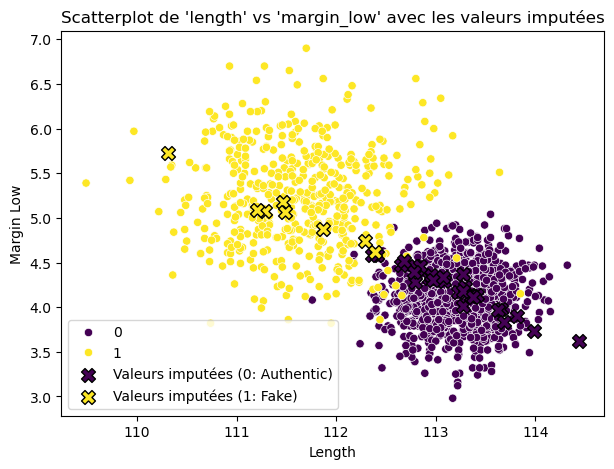

<Figure size 640x480 with 0 Axes>

In [ ]:
# Afficher une scatterplot entre 'length' et 'margin_low' avec les valeurs imputées
colors = {1: "#21918C", 0: "#FDE725"}
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='length', y='margin_low', hue='is_Fake', palette = colors)

# Afficher les valeurs imputées avec des couleurs différentes selon is_Fake
#colors = {0: (0.993248, 0.906157, 0.143936, 1.0), 1: (0.267004, 0.004874, 0.329415, 1.0)}
for genuine_value in [0, 1]:
    mask = missing_mask & (df['is_Fake'] == genuine_value)
    label_text = f"Valeurs imputées ({'0: Authentic' if genuine_value == 0 else '1: Fake'})"
    plt.scatter(df[mask]['length'], df[mask]['margin_low'], 
                marker='X', s=100, color=colors[genuine_value], 
                label=label_text, edgecolors='black', linewidth=1)

plt.title("Scatterplot de 'length' vs 'margin_low' avec les valeurs imputées")
plt.xlabel('Length')
plt.ylabel('Margin Low')
plt.legend()
plt.show()
plt.savefig("Figures/fig_imputation.jpeg",bbox_inches="tight")

Toutes les variables présentent une distribution très symétrique (normale) 
avec quelques valeurs aberrantes. 

Nous prévoyons que les variables présentant la plus grande différence de mesures 
entre les billets authentiques et contrefaits auront la plus grande valeur prédictive. 

Les variables sont, par ordre décroissant : 

Length > Inner margin > Upper margin > Height right > Height left > Diagonal


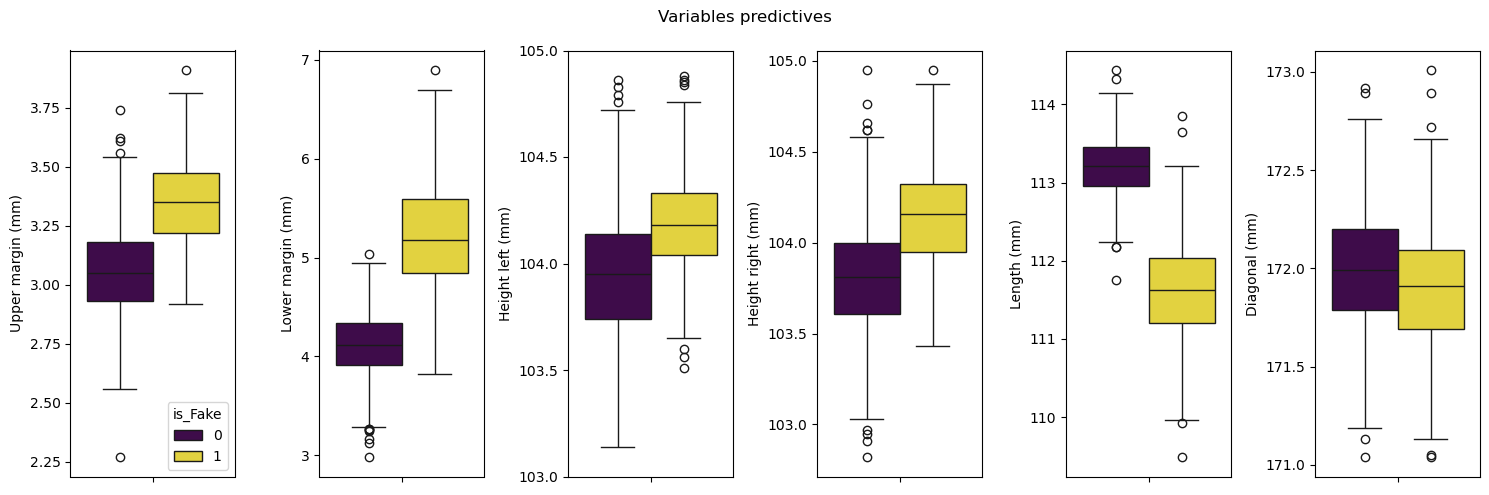

In [80]:
# Exploration visuelle de l'ensemble des données
# Boxplots
#plt.figure(figsize=(10, 6))
colors = {(0.993248, 0.906157, 0.143936, 1.0),(0.267004, 0.004874, 0.329415, 1.0)}
fig, (ax1,ax2,ax3,ax4,ax5,ax6)  = plt.subplots(1,6, figsize=(15,5))
#fig.figsize(10,6)
fig.suptitle("Variables predictives")

sns.boxplot(y="margin_up", data=df,  hue="is_Fake", orient='v' , ax=ax1, palette=colors)
ax1.set(ylabel="Upper margin (mm)")

sns.boxplot(y="margin_low", data=df,  hue="is_Fake", orient='v' , ax=ax2, palette=colors, legend=False)
ax2.set(ylabel="Lower margin (mm)", yticks=(range(3,8)))

sns.boxplot(y="height_left", data=df,  hue="is_Fake", orient='v' , ax=ax3, palette=colors, legend=False)
ax3.set(ylabel="Height left (mm)", yticks=(np.arange(103,105.5,0.5)))
#[103,103.5,104,104.5,105]
sns.boxplot(y="height_right", data=df,  hue="is_Fake", orient='v' , ax=ax4, palette=colors, legend=False)
ax4.set(ylabel="Height right (mm)")

sns.boxplot(y="length", data=df,  hue="is_Fake", orient='v' , ax=ax5, palette=colors, legend=False)
ax5.set(ylabel="Length (mm)")

sns.boxplot(y="diagonal", data=df,  hue="is_Fake", orient='v' , ax=ax6, palette=colors, legend=False)
ax6.set(ylabel="Diagonal (mm)", yticks=(np.arange(171,173.5,0.5)))

fig.tight_layout()
plt.savefig("Figures/fig_variables_predictives.jpeg",bbox_inches="tight")

print("Toutes les variables présentent une distribution très symétrique (normale) \navec quelques valeurs aberrantes. \n\nNous prévoyons que les variables présentant la plus grande différence de mesures \nentre les billets authentiques et contrefaits auront la plus grande valeur prédictive. \n\nLes variables sont, par ordre décroissant : \n\nLength > Inner margin > Upper margin > Height right > Height left > Diagonal")

In [81]:
# Sauvgarder les données complete
df_complete = df
df_complete.to_csv("Donnees_resultats/df_complete.csv", sep=";", index=False)

In [82]:
# Telecharger les données complete avec imputations
#DATA_PATH = "Donnees_resultats/df_complete.csv"
#df1 = pd.read_csv(DATA_PATH, sep=";", header=0)


# 3) Prétraitement

Dans la phase de prétraitement, on 
1) définis les variables (cible et prédicteurs), 
2) j'effectue la division des données en ensembles d'entraînement et de test, et 
3) je normalise les données pour faciliter l'entraînement des modèles ML.

In [83]:
# Definir les variables predictive X et la variable cible y                             
X = df.drop(columns=["is_genuine", "is_Fake"]) # Toutes les colonnes sauf la cible
X.columns = df.drop(columns=["is_genuine", "is_Fake"]).columns
y = df["is_Fake"] # La colonne cible binaire

In [84]:
# Split le donnée dans train et test (split avant le normalisation!)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(X, y, test_size=0.2, random_state=42)

In [85]:
# Normaliser les variables explicatives (X), i.e., met les variables sur la meme echelle, pour que les modèles de machine learning puissent mieux apprendre
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)                     
X_test = scaler.transform(X_test_raw)    # Then perform normalisation on testing instances as well, but this time using the mean and variance of training explanatory variables
X_train = pd.DataFrame(X_train, columns = X.columns)
X_test = pd.DataFrame(X_test, columns = X.columns)
y_train = y_train_raw    # ne pas normaliser la variable cible (y), car c'est une variable binaire
y_test = y_test_raw
X_train.head(3)

,diagonal,height_left,height_right,margin_low,margin_up,length
0,1.050853,1.958416,-0.367712,-0.597822,-0.306118,0.648529
1,-0.185700,1.559864,-1.317963,-0.597822,-1.428167,0.921625
2,-1.064303,0.995247,2.115204,0.618920,0.859087,-0.603164


In [86]:
# faire le normalisation apres le train test split.
# "jamais le fit avant le split"...

# 4) Modélisation

Dans la phase de modélisation, on 
1) faire un cross validation pour trouves le meilleurs hyperparametres, 
2) afficher et verifier (avec leurs diagnostics) le "meilleur" model avec des parametres optimise,
3) comprendre la contribution des différentes variables/features à la prédiction du modèle avec graphique, 
4) ajuster le seuil de décision dans le but de maximiser le "recall",
5) afficher et verifier (leur diagnostique) le model final avec des parametres et un seuil de décision optimal,
6) pour les meilleurs modèles, sauvez-les avec leur "pipeline".

In [87]:
# Fonction pour:
# Validation croisée pour identifier les hyperparamètres
# model : le modèle non entraîné
# param_grid : un dictionnaire contenant les noms des paramètres et leur plage de valeurs
# name : string contenant le nom du modèle (ex, régression logistique, random forest)

def run_grid_search_CV(model, param_grid, name):
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring='roc_auc',
        cv=5,
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    print("Meilleur params", model_name, ":", grid.best_params_)
    print("Meilleur CV AUC pour",  model_name, ":", grid.best_score_)

    best_model = grid.best_estimator_
    best_model.fit(X_train, y_train)

    return best_model


# 4.1) Regression Logistique

<div style="border: 2px solid RGB(255,255,255);" >


4.1.1) Validation croisée

Identifier le hyperpara$etres à l'aide du "roc_auc" validé par validation croisée


In [88]:
# Paramètres à prendre en compte et leur importance:

# C : Force de la régularisation (plus petit = régularisation plus forte)
# penalty : Régularisation L1 ou L2
# solver: doit correspondre au type de pénalité
# class_weight : Important pour les données de fraude déséquilibrées

model_name = "Logistic Regression"
log_reg = LogisticRegression(max_iter=500, random_state=42)

param_grid_lr = {  
    'C': [0.01, 0.1, 1, 10], # C est l'inverse de l'intensité de la régularisation (réduire le overfitting). Si élevée = régularisation faible, si faible = régularisation forte. Default = 1
    'penalty': ['l2'],   # default
    'solver': ['lbfgs'], # default
    'class_weight': ['balanced'] # important pour les données déséquilibrées, comme dans notre cas, où les données sur les billets de banque frauduleux sont moins nombreuses
}

best_model_lr = run_grid_search_CV(log_reg, param_grid_lr, model_name)   


Meilleur params Logistic Regression : {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'lbfgs'}
Meilleur CV AUC pour Logistic Regression : 0.9988445710667933


4.1.2)
Afficher le "meilleur" model avec des parametres optimise


In [89]:
grid = GridSearchCV(
        estimator=log_reg,
        param_grid=param_grid_lr,
        scoring='roc_auc',
        cv=5,
        n_jobs=-1
)

grid.fit(X_train, y_train)

print("Meilleur params", model_name, ":", grid.best_params_)
print("Meilleur CV AUC pour",  model_name, ":", grid.best_score_)

best_model_lr.fit(X_train, y_train)

cv_results = pd.DataFrame(grid.cv_results_)
#cv_results


Meilleur params Logistic Regression : {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'lbfgs'}
Meilleur CV AUC pour Logistic Regression : 0.9988445710667933


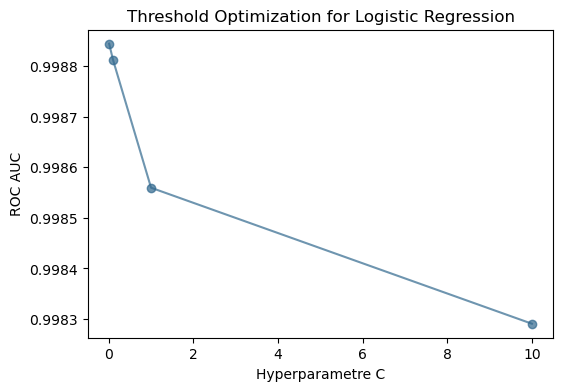

In [90]:
# Exapmle de graphique de ROC AUC en fonction du valeur de hyperparametre C pour la régression logistique
plt.figure(figsize=(6, 4))

cmap = plt.get_cmap("viridis_r")
colors = [cmap(x) for x in np.linspace(0, 1, 5)]


plt.plot(cv_results['param_C'], cv_results['mean_test_score'], 
         label='Accuracy', color='#31688E', marker='o', alpha=0.7)

plt.xlabel('Hyperparametre C')
plt.ylabel('ROC AUC')
plt.title('Threshold Optimization for Logistic Regression')
#plt.legend()
#plt.grid(True)
plt.savefig("Figures/fig_param_optim_log_reg.jpeg",bbox_inches="tight")
plt.show()

Logistic Regression
Accuracy 0.993
Precision regression logistique : 0.991
Recall regression logistique : 0.991

Classification report pour le meilleur logistic regression:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       190
           1       0.99      0.99      0.99       110

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



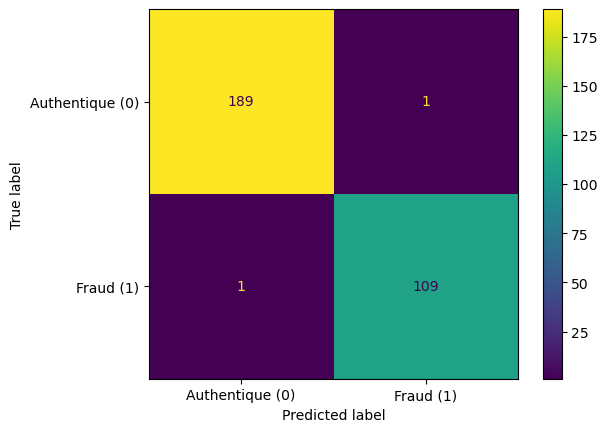

Text(0, 0.5, 'Taux de vrais positifs (TPR)')

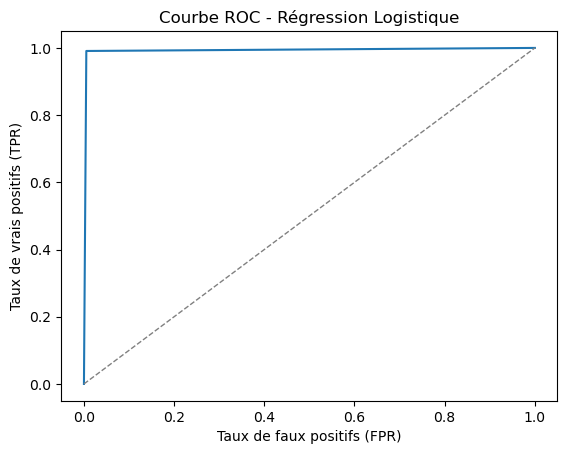

In [91]:
# Le "meilleur" model avec des parametres optimise

# Regression logistic avec meilleur seuil
# Prédire les classes pour les données de test
y_lr = best_model_lr.predict(X_test)         

print(model_name)
print(f"Accuracy {accuracy_score(y_test, y_lr):.3f}")
print(f"Precision regression logistique : {precision_score(y_test,y_lr, pos_label=True):.3f}")
print(f"Recall regression logistique : {recall_score(y_test, y_lr, pos_label=True):.3f}")

print()
print("Classification report pour le meilleur logistic regression:")
print(classification_report(y_test, y_lr))

# Matrice de confusion
#print(f"Matrice de confusions regression logistique:\n", confusion_matrix(y_test, y_logist))
cm = confusion_matrix(y_test, y_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Authentique (0)', 'Fraud (1)'])
disp.plot()
plt.savefig("Figures/fig_confusion_matrix_param_lr.jpeg",bbox_inches="tight")
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_lr)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
plt.title("Courbe ROC - Régression Logistique")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")

4.1.3
Comprendre la contribution des différentes variables/features à la prédiction du modèle avec graphique SHAP 


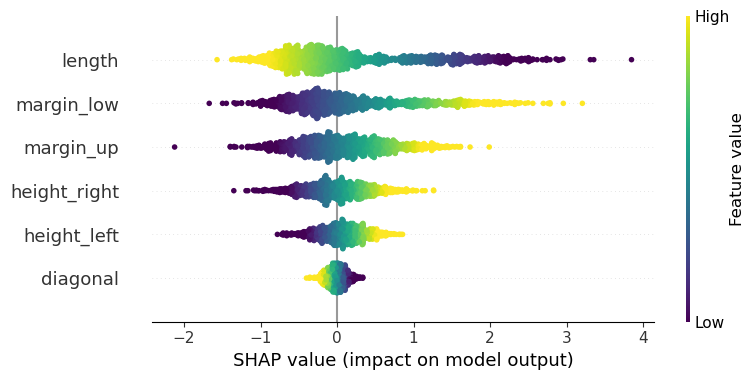

In [92]:
# Comprendre la contribution des différentes variables/features à la prédiction du modèle avec graphique SHAP 

mpl.rcParams['image.cmap'] = 'viridis'

explainer = shap.LinearExplainer(best_model_lr, X_train) 
shap_values = explainer.shap_values(X_train)

shap.summary_plot(shap_values, X_train, cmap='viridis')


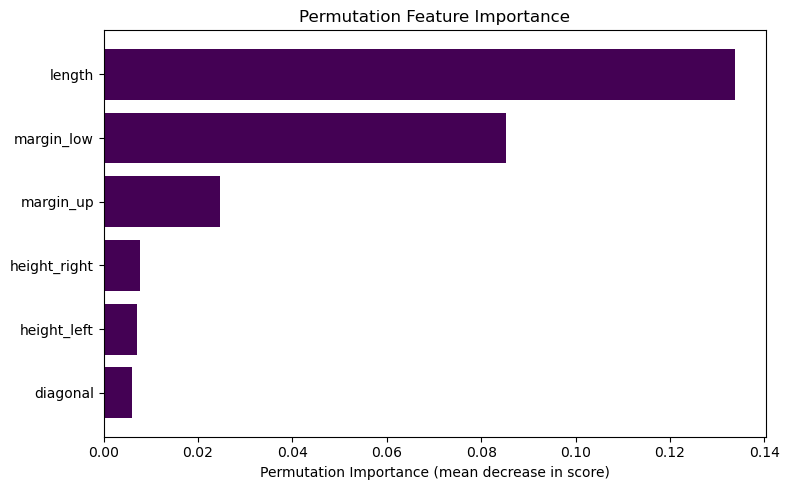

In [93]:
# Importance permutation

result = permutation_importance(
    best_model_lr, X_test, y_test,
    n_repeats=10,
    random_state=42
)

perm_importances = result.importances_mean
indices = np.argsort(perm_importances)

plt.figure(figsize=(8, 5))
plt.barh(range(len(perm_importances)), perm_importances[indices], color='#440154')
plt.yticks(range(len(perm_importances)), X.columns[indices])
plt.xlabel("Permutation Importance (mean decrease in score)")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.savefig("Figures/fig_feature_importance_lr.jpeg",bbox_inches="tight")
plt.show()


4.1.4)
Ajuster le seuil de décision

Best threshold: 0.31
threshold    0.310000
accuracy     0.976667
precision    0.940171
recall       1.000000
Name: 30, dtype: float64


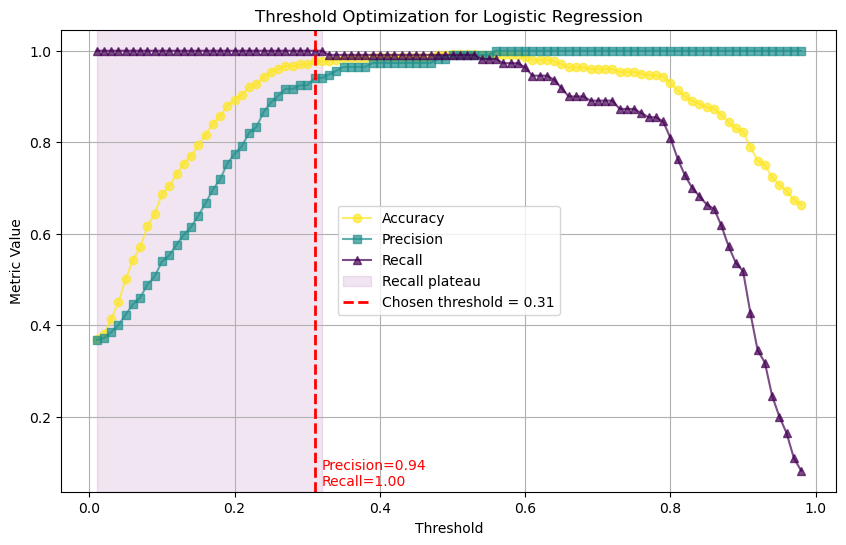

In [94]:
# Ajuster le seuil de décision
# Maximiser le rappel (pour éviter les faux négatifs) tout en maintenant la précision au plus haut niveau possible.

# calculer les métriques pour chaque seuil
y_proba = best_model_lr.predict_proba(X_test)[:, 1] 
thresholds = np.arange(0.01, 0.99, 0.01)

results = []

for t in thresholds:
    preds = (y_proba >= t).astype(int)
    results.append({
        'threshold': t,
        'accuracy': accuracy_score(y_test, preds),
        'precision': precision_score(y_test, preds),
        'recall': recall_score(y_test, preds)
    })

threshold_metrics = pd.DataFrame(results)

# Identifier le plateau de rappel
max_recall = threshold_metrics['recall'].max()
plateau = threshold_metrics[threshold_metrics['recall'] == max_recall]

# Choisissez le seuil avec la plus grande précision à l'intérieur du plateau
best_row = plateau.loc[plateau['precision'].idxmax()]
best_t_lr = best_row['threshold']

print("Best threshold:", best_t_lr)
print(best_row)

#display(threshold_metrics)

# Graphique des métriques en fonction du seuil
plt.figure(figsize=(10, 6))

cmap = plt.get_cmap("viridis_r")
colors = [cmap(x) for x in np.linspace(0, 1, 3)]


plt.plot(threshold_metrics['threshold'], threshold_metrics['accuracy'], 
         label='Accuracy', color=colors[0], marker='o', alpha=0.7)
plt.plot(threshold_metrics['threshold'], threshold_metrics['precision'], 
         label='Precision', color=colors[1], marker='s', alpha=0.7)
plt.plot(threshold_metrics['threshold'], threshold_metrics['recall'], 
         label='Recall', color=colors[2], marker='^', alpha=0.7)

# Le plateau
plt.axvspan(plateau['threshold'].min(), plateau['threshold'].max(), 
            color='purple', alpha=0.1, label='Recall plateau')

# Ligne verticale au seuil choisi
plt.axvline(best_t_lr, color='red', linestyle='--', linewidth=2, 
            label=f'Chosen threshold = {best_t_lr:.2f}')

plt.text(best_t_lr  + 0.01, 0.05, 
         f"Precision={best_row['precision']:.2f}\nRecall={best_row['recall']:.2f}",
         color='red')

plt.xlabel('Threshold')
plt.ylabel('Metric Value')
plt.title('Threshold Optimization for Logistic Regression')
plt.legend()
plt.grid(True)
plt.savefig("Figures/fig_threshold_log_reg.jpeg",bbox_inches="tight")
plt.show()


4.1.5)
Afficher le modèle final, qui maximise le recall/rappel afin d'éviter les faux négatifs.

Threshold Logistic Regression : 0.31
Accuracy 0.977
Precision regression logistique : 0.940
Recall regression logistique : 1.000

Classification report pour le meilleur logistic regression:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98       190
           1       0.94      1.00      0.97       110

    accuracy                           0.98       300
   macro avg       0.97      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300



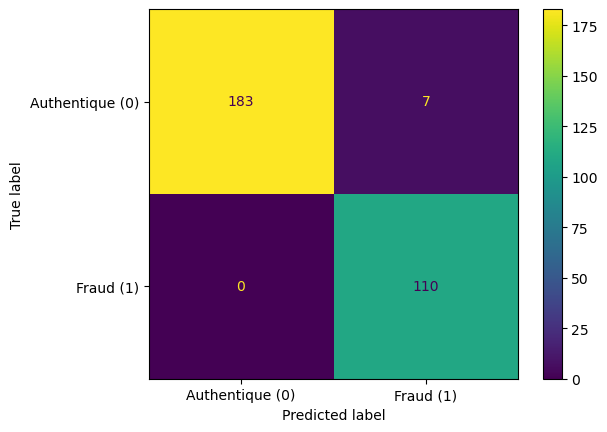

Text(0, 0.5, 'Taux de vrais positifs (TPR)')

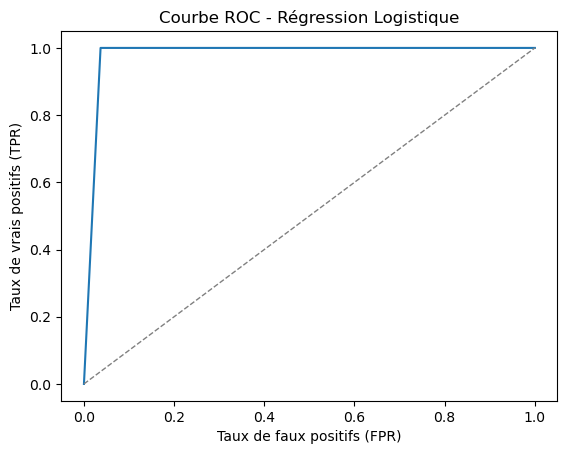

In [95]:
# Le model final!
# Regression logistic avec meilleur seuil
# y_pred_thresh = y_logist_proba >= 0.1
y_preds_final = (y_proba >= best_t_lr).astype(int)

print('Threshold',model_name,":",best_t_lr)
print(f"Accuracy {accuracy_score(y_test, y_preds_final):.3f}")
print(f"Precision regression logistique : {precision_score(y_test, y_preds_final, pos_label=True):.3f}")
print(f"Recall regression logistique : {recall_score(y_test, y_preds_final, pos_label=True):.3f}")

print()
print("Classification report pour le meilleur logistic regression:")
print(classification_report(y_test, y_preds_final))

# Matrice de confusion
#print(f"Matrice de confusions regression logistique:\n", confusion_matrix(y_test, y_logist))
cm = confusion_matrix(y_test, y_preds_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Authentique (0)', 'Fraud (1)'])
disp.plot()
plt.savefig("Figures/fig_confusion_matrix_param_seuil_lr.jpeg",bbox_inches="tight")
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_preds_final)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
plt.title("Courbe ROC - Régression Logistique")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")


4.1.6) Sauvegarder le modèle final (avec joblib) avec son "pipeline" pour une utilisation future

In [96]:
# Pipeline regression logistique avec les meilleurs paramètres

pipe_lr = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter=500, random_state=42)
)

best_params_lr = {
    "logisticregression__C": 1.0,
    "logisticregression__penalty": "l2",
    "logisticregression__solver": "lbfgs",
    "logisticregression__class_weight": "balanced"
}

pipe_lr.set_params(**best_params_lr)
pipe_lr.fit(X_train_raw, y_train_raw)    # sauvgardes les raw X_train et X_test 


,steps,"[('standardscaler', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [97]:
# Souvgarder le model regression logistique avec joblib
joblib.dump(pipe_lr, "Donnees_resultats/model_billet_fraud_lr.pkl")


['Donnees_resultats/model_billet_fraud_lr.pkl']

# 4.2) K-nearest neighbour (KNN)

<div style="border: 2px solid RGB(255,255,255);" >


4.2.1) Validation croisée

Identifier le meilleur modèle à l'aide du "roc_auc" validé par validation croisée

In [98]:
# KNN
# Cross validation des parametres

# Paramètres à prendre en compte et leur importance:
# n_neigbors : "K" nombre de voisins
# weights : uniform ou distance, 

model_name = "KNN"
knn = KNeighborsClassifier()

param_grid_knn = {  
    "n_neighbors": list(range(1, 16, 1)), # « k » représente le nombre de voisins les plus proches considérés dans le problème de classification (default = 5)
    "weights": ["uniform", "distance"]    # si la valeur des pondérations est « distance », cela signifie que les voisins les plus proches d'un point de requête auront une plus grande influence que les voisins plus éloignés (default = uniform)
}

best_model_knn = run_grid_search_CV(knn, param_grid_knn, model_name)

Meilleur params KNN : {'n_neighbors': 13, 'weights': 'uniform'}
Meilleur CV AUC pour KNN : 0.9953070591959481


4.2.2) 
Afficher le "meilleur" model avec des parametres optimise

KNN
Accuracy 0.987
Precision KNN : 1.000
Recall KNN : 0.964

Classification report pour le meilleur KNN:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       190
           1       1.00      0.96      0.98       110

    accuracy                           0.99       300
   macro avg       0.99      0.98      0.99       300
weighted avg       0.99      0.99      0.99       300

Matrice de confusions KNN:


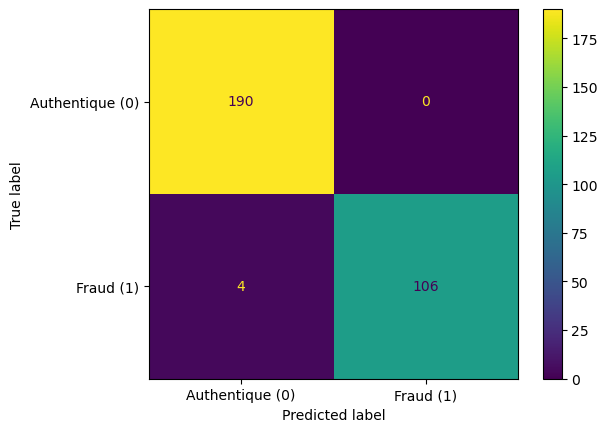

Text(0, 0.5, 'Taux de vrais positifs (TPR)')

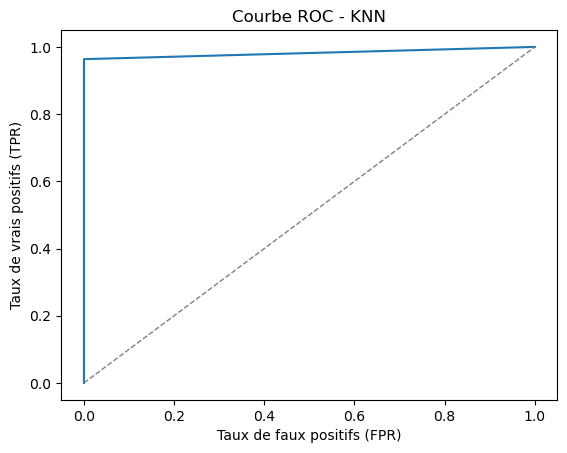

In [99]:
# KNN avec parametres optimise
# Prédire les classes pour les données de test
y_knn = best_model_knn.predict(X_test)     

print(model_name)
print(f"Accuracy {accuracy_score(y_test, y_knn):.3f}")
print(f"Precision KNN : {precision_score(y_test,y_knn, pos_label=True):.3f}")
print(f"Recall KNN : {recall_score(y_test, y_knn, pos_label=True):.3f}")

print()
print("Classification report pour le meilleur KNN:")
print(classification_report(y_test, y_knn))

# Matrice de confusion
print("Matrice de confusions KNN:")
cm = confusion_matrix(y_test, y_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Authentique (0)', 'Fraud (1)'])
disp.plot()
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_knn)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
plt.title("Courbe ROC - KNN")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")


4.2.3)
Comprendre la contribution des différentes variables/features à la prédiction du modèle

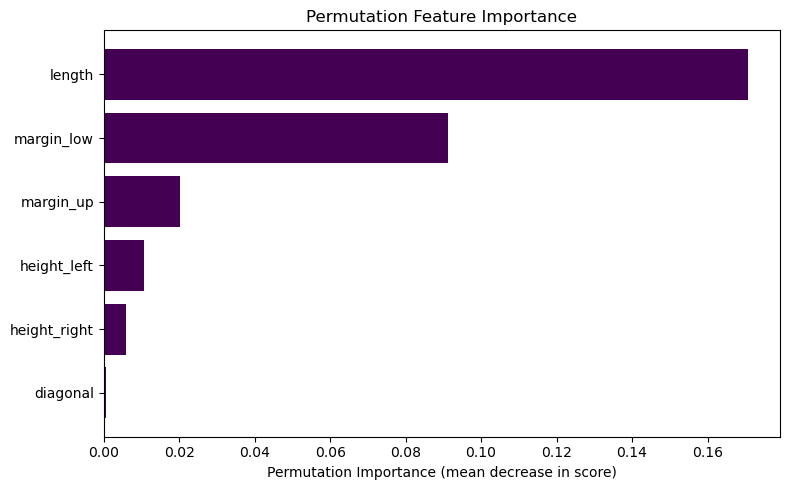

In [100]:
# Importance permutation


result = permutation_importance(
    best_model_knn, X_test, y_test,
    n_repeats=10,
    random_state=42
)

perm_importances = result.importances_mean
indices = np.argsort(perm_importances)

plt.figure(figsize=(8, 5))
plt.barh(range(len(perm_importances)), perm_importances[indices], color='#440154')
plt.yticks(range(len(perm_importances)), X.columns[indices])
plt.xlabel("Permutation Importance (mean decrease in score)")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.savefig("Figures/fig_feature_importance_KNN.jpeg",bbox_inches="tight")
plt.show()


4.2.4)
Ajuster le seuil de décision

Best threshold: 0.15000000000000002
threshold    0.150000
accuracy     0.990000
precision    0.973451
recall       1.000000
Name: 14, dtype: float64


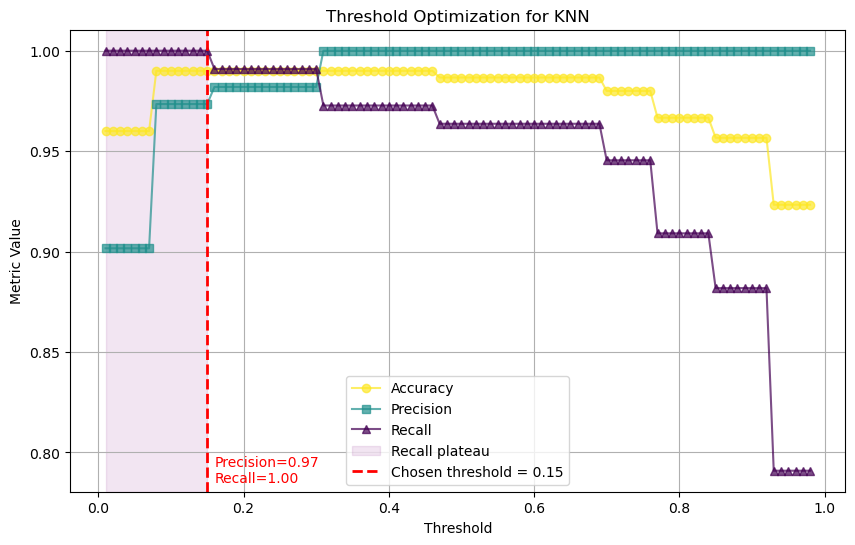

In [101]:
# Ajuster le seuil de décision
# Maximiser le rappel (pour éviter les faux négatifs) tout en maintenant la précision au plus haut niveau possible.

# calculer les métriques pour chaque seuil
y_proba = best_model_knn.predict_proba(X_test)[:, 1]
thresholds = np.arange(0.01, 0.99, 0.01)

results = []

for t in thresholds:
    preds = (y_proba >= t).astype(int)
    results.append({
        'threshold': t,
        'accuracy': accuracy_score(y_test, preds),
        'precision': precision_score(y_test, preds),
        'recall': recall_score(y_test, preds)
    })

threshold_metrics = pd.DataFrame(results)

# plateau de recall 
max_recall = threshold_metrics['recall'].max()
plateau = threshold_metrics[threshold_metrics['recall'] == max_recall]

# plateau de precision dans le plateau de recall 
max_precision = plateau['precision'].max()
double_plateau = plateau[plateau['precision'] == max_precision]

# seils max 
best_row = double_plateau.loc[double_plateau['threshold'].idxmax()]
best_t_knn = best_row['threshold']

print("Best threshold:", best_t_knn)
print(best_row)

# Graphique des métriques en fonction du seuil
plt.figure(figsize=(10, 6))

cmap = plt.get_cmap("viridis_r")
colors = [cmap(x) for x in np.linspace(0, 1, 3)]


plt.plot(threshold_metrics['threshold'], threshold_metrics['accuracy'], 
         label='Accuracy', color=colors[0], marker='o', alpha=0.7)
plt.plot(threshold_metrics['threshold'], threshold_metrics['precision'], 
         label='Precision', color=colors[1], marker='s', alpha=0.7)
plt.plot(threshold_metrics['threshold'], threshold_metrics['recall'], 
         label='Recall', color=colors[2], marker='^', alpha=0.7)

# Le plateau
plt.axvspan(plateau['threshold'].min(), plateau['threshold'].max(), 
            color='purple', alpha=0.1, label='Recall plateau')

# Ligne verticale au seuil choisi
plt.axvline(best_t_knn, color='red', linestyle='--', linewidth=2, 
            label=f'Chosen threshold = {best_t_knn:.2f}')

plt.text(best_t_knn  + 0.01, 0.785, 
         f"Precision={best_row['precision']:.2f}\nRecall={best_row['recall']:.2f}",
         color='red')

plt.xlabel('Threshold')
plt.ylabel('Metric Value')
plt.title('Threshold Optimization for KNN')
plt.legend()
plt.grid(True)
plt.savefig("Figures/fig_threshold_KNN.jpeg",bbox_inches="tight")
plt.show()



4.1.5)
Afficher le modèle final, qui maximise le recall/rappel afin d'éviter les faux négatifs.

Threshold KNN : 0.15000000000000002
Accuracy 0.990
Precision KNN : 0.973
Recall KNN : 1.000

Classification report pour le meilleur KNN:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       190
           1       0.97      1.00      0.99       110

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



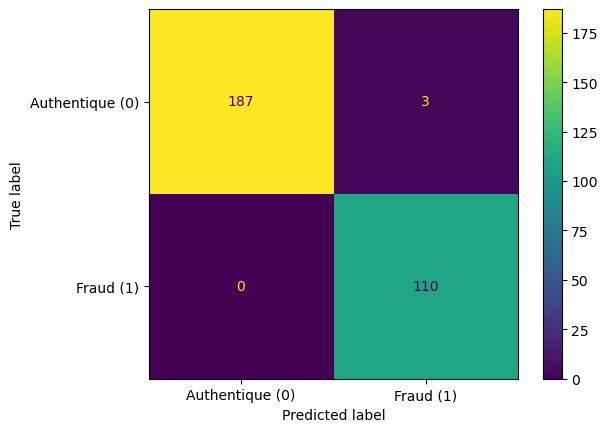

Text(0, 0.5, 'Taux de vrais positifs (TPR)')

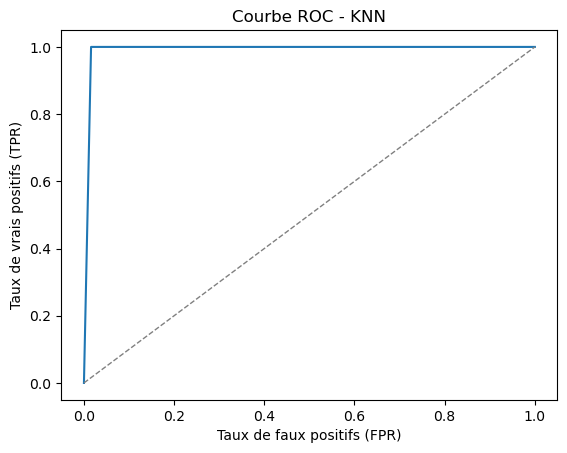

In [102]:
# Le model final!
# KNN avec meilleur seuil
y_preds_final = (y_proba >= best_t_knn).astype(int)

print('Threshold',model_name,":",best_t_knn)
print(f"Accuracy {accuracy_score(y_test, y_preds_final):.3f}")
print(f"Precision KNN : {precision_score(y_test, y_preds_final, pos_label=True):.3f}")
print(f"Recall KNN : {recall_score(y_test, y_preds_final, pos_label=True):.3f}")

print()
print("Classification report pour le meilleur KNN:")
print(classification_report(y_test, y_preds_final))

# Matrice de confusion
#print(f"Matrice de confusions regression logistique:\n", confusion_matrix(y_test, y_logist))
cm = confusion_matrix(y_test, y_preds_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Authentique (0)', 'Fraud (1)'])
disp.plot()
plt.savefig("Figures/fig_confusion_matrix_param_seuil_knn.jpeg",bbox_inches="tight")
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_preds_final)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
plt.title("Courbe ROC - KNN")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")



4.2.6) Sauvegarder le modèle final (avec joblib) avec son "pipeline" pour une utilisation future

In [103]:
# Faire une Pipeline KNN
pipe_knn = make_pipeline(StandardScaler(),
                        KNeighborsClassifier()
)

best_params_knn = {
    "kneighborsclassifier__n_neighbors": 13,
    "kneighborsclassifier__weights": "uniform"
}   

pipe_knn.set_params(**best_params_knn)
pipe_knn.fit(X_train_raw, y_train_raw)


,steps,"[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,13
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


In [104]:
# Souvgarder le model KNN avec joblib, et le X_train et y_train  
joblib.dump(pipe_knn,"Donnees_resultats/model_billet_fraud_knn.pkl")
joblib.dump((X_train_raw, X_test_raw), "Donnees_resultats/X_train_test_raw_data_knn.pkl")


['Donnees_resultats/X_train_test_raw_data_knn.pkl']

# 4.3) K-means

<div style="border: 2px solid RGB(255,255,255);" >

4.3.1) K-means n'est pas un classificateur. L'identification des clusters peut toutefois être utilisée, et des étiquettes frauduleuses et authentiques peuvent être attribuées à ces clusters.

c:\Users\matil\anaconda3\envs\ML_basics\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


              precision    recall  f1-score   support

           0       0.99      0.99      0.99       190
           1       0.98      0.99      0.99       110

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300

Les performances globales sont bonnes, comme en témoigne la grande accuracy (0.99). 
Cependant, il n'est pas possible d'ajuster finement les valeurs de recall/rappel, 
qui sont supérieures à celles des autres modèles.


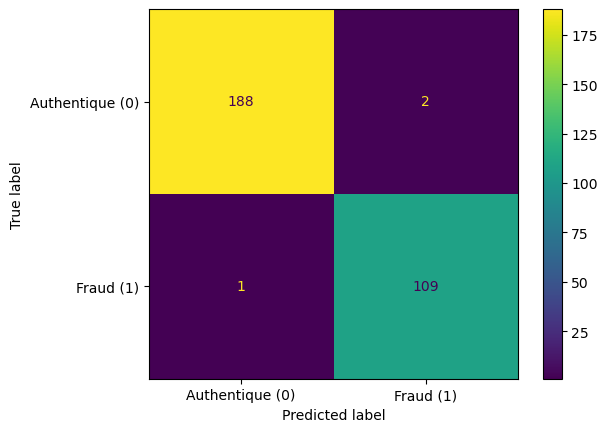

In [105]:
# K-means clustering
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X_train)

cluster_labels = kmeans.predict(X_test) # Les étiquettes sont arbitraires

# nous déterminons quel groupe correspond à la fraude par vote majoritaire.
mapping = {}

for cluster in np.unique(cluster_labels):
    # majority class inside this cluster
    majority_class = y_test[cluster_labels == cluster].mode()[0]
    mapping[cluster] = majority_class


# convertir les étiquettes de cluster en classes prédites
y_pred = pd.Series(cluster_labels).map(mapping)
y_pred

print(classification_report(y_test, y_pred))

print("Les performances globales sont bonnes, comme en témoigne la grande accuracy (0.99). \nCependant, il n'est pas possible d'ajuster finement les valeurs de recall/rappel, \nqui sont supérieures à celles des autres modèles.")

# Matrice de confusion
#print(f"Matrice de confusions regression logistique:\n", confusion_matrix(y_test, y_logist))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Authentique (0)', 'Fraud (1)'])
disp.plot()
plt.savefig("Figures/fig_confusion_matrix_param_seuil_Kmeans.jpeg",bbox_inches="tight")
plt.show()


# ajouter une plot avec les clusters

c:\Users\matil\anaconda3\envs\ML_basics\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


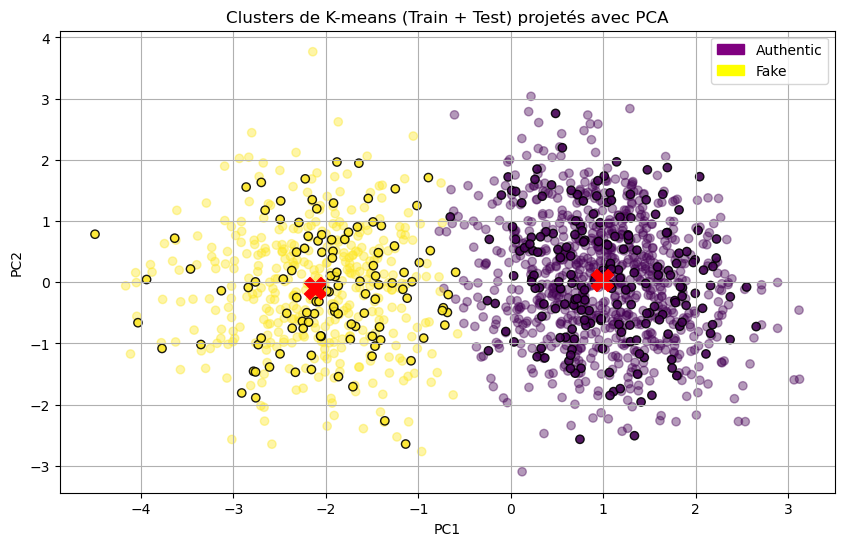

In [106]:
# Visualier les clusters K-means et ces centroids avec PCA

# Fit PCA sur le données d'entraînement 
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Predire clusters pour tout les deux jeux de données (X_train et X_test)
train_clusters = kmeans.predict(X_train)
test_clusters = kmeans.predict(X_test)

# Projection des centroids
centroids_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(10,6))

# Données d'entraînement
plt.scatter(
    X_train_pca[:,0], X_train_pca[:,1],
    c=train_clusters,
    cmap='viridis_r',
    alpha=0.4,
    label='Train'
)

# Données de test
plt.scatter(
    X_test_pca[:,0], X_test_pca[:,1],
    c=test_clusters,
    cmap='viridis_r',
    alpha=0.9,
    marker='o',
    edgecolor='black',
    label='Test'
)

# Données de centroids
plt.scatter(
    centroids_pca[:,0], centroids_pca[:,1],
    c='red', s=250, marker='X', label='Centroids'
)

# Légende personnalisée
purple_patch = mpatches.Patch(color='purple', label='Authentic')
yellow_patch = mpatches.Patch(color='yellow', label='Fake')

plt.legend(handles=[purple_patch, yellow_patch])

plt.title("Clusters de K-means (Train + Test) projetés avec PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.show()

# 4.4) Random Forest

<div style="border: 2px solid RGB(255,255,255);" >

4.4.1) Validation croisée

Identifier le meilleur modèle à l'aide du "roc_auc" validé par validation croisée

In [107]:
# Random Forest
# Cross validation des parametres

# Paramètres à prendre en compte et leur importance:
# n_estimators : le nombre d'arbres de décision dans la forêt
# max_depth : la profondeur maximale de chaque arbre de décision dans la forêt
# min_samples_split : le nombre minimal d'échantillons requis pour diviser un nœud interne
# class_weight : généralement utilisé lorsqu'il existe un déséquilibre dans la répartition des catégories. Important pour les données de fraude déséquilibrées

model_name = "Random Forest"
forest = RandomForestClassifier(random_state=42)

param_grid_rf = {  
    "n_estimators": [100, 300, 500], # modèle stable vs entraînement lent (100-500)
    "max_depth": [None, 5, 10, 20],  # overfitting (forte valeur) vs underfitting (faible valeur)
    "min_samples_split": [2, 5, 10], # default = 2
    "class_weight": [None,"balanced"] #  Important pour les données de fraude déséquilibrées
}

best_model_rf = run_grid_search_CV(forest, param_grid_rf, model_name) 

# min_samples_split # Nombre minimal d'échantillons pour diviser un nœud : des valeurs plus élevées → arbres plus simples, moins de surapprentissage
# min_samples_leaf # Nombre minimal d'échantillons dans une feuille. Évite la mémorisation du bruit par les petites feuilles 
# max_features # Nombre de caractéristiques considérées à chaque division. « sqrt » est la valeur par défaut et souvent la plus adaptée « log2 » ou un nombre décimal (par exemple, 0,5) peut améliorer la généralisation

Meilleur params Random Forest : {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_split': 10, 'n_estimators': 100}
Meilleur CV AUC pour Random Forest : 0.9996201329534664


4.4.2)
Afficher le "meilleur" model avec des parametres optimise

Random Forest
Accuracy 0.993
Precision Random Forest : 1.000
Recall Random Forest : 0.982

Classification report pour le meilleur random forest:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       190
           1       1.00      0.98      0.99       110

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



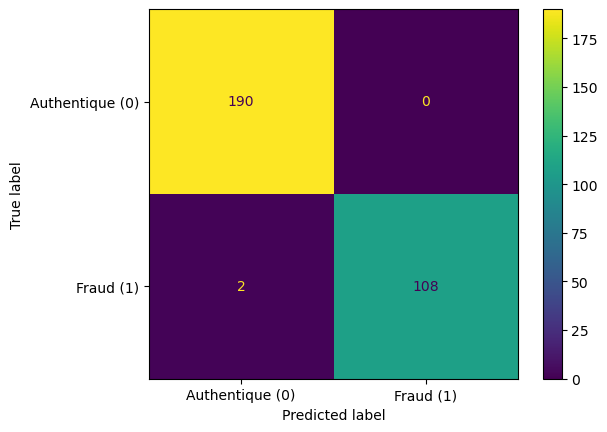

Text(0, 0.5, 'Taux de vrais positifs (TPR)')

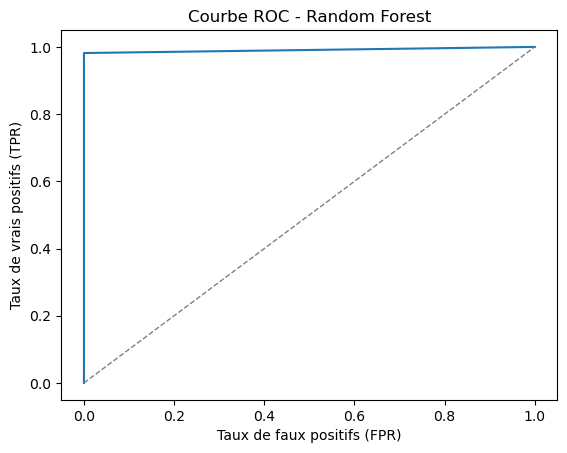

In [108]:
# Meilleur model Random Forest avec parametres optimise avec ROC AUC
# Prédire les classes pour les données de test
y_rf = best_model_rf.predict(X_test)   

print(model_name)
print(f"Accuracy {accuracy_score(y_test, y_rf):.3f}")
print(f"Precision Random Forest : {precision_score(y_test,y_rf, pos_label=True):.3f}")
print(f"Recall Random Forest : {recall_score(y_test, y_rf, pos_label=True):.3f}")

print()
print("Classification report pour le meilleur random forest:")
print(classification_report(y_test, y_rf))

# Matrice de confusion
#print(f"Matrice de confusions Random Forest:\n", confusion_matrix(y_test, y_logist))
cm = confusion_matrix(y_test, y_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Authentique (0)', 'Fraud (1)'])
disp.plot()
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_rf)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
plt.title("Courbe ROC - Random Forest")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")


5.4.3)
Comprendre la contribution des différentes variables/features à la prédiction du modèle

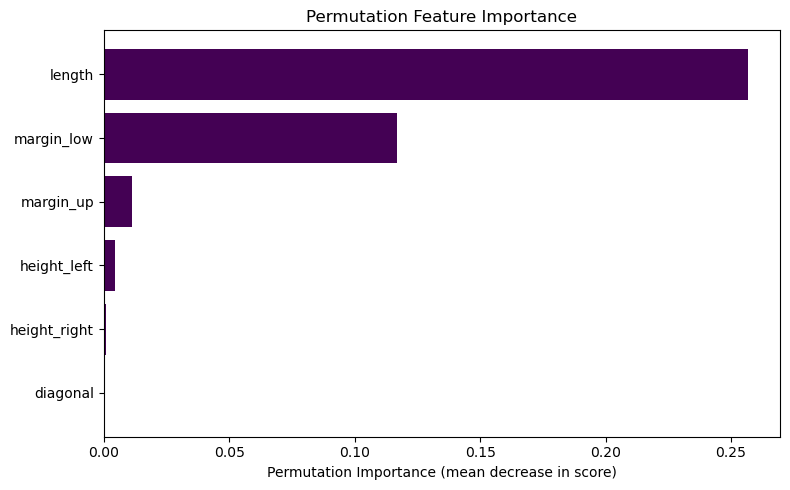

In [109]:
# Importance permutation

result = permutation_importance(
    best_model_rf, X_test, y_test,
    n_repeats=10,
    random_state=42
)

perm_importances = result.importances_mean
indices = np.argsort(perm_importances)

plt.figure(figsize=(8, 5))
plt.barh(range(len(perm_importances)), perm_importances[indices], color='#440154')
plt.yticks(range(len(perm_importances)), X.columns[indices])
plt.xlabel("Permutation Importance (mean decrease in score)")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.savefig("Figures/fig_feature_importance_rf.jpeg",bbox_inches="tight")
plt.show()


4.4.4)
Ajuster le seuil de décision

Best threshold: 0.32
threshold    0.320000
accuracy     0.993333
precision    0.982143
recall       1.000000
Name: 31, dtype: float64


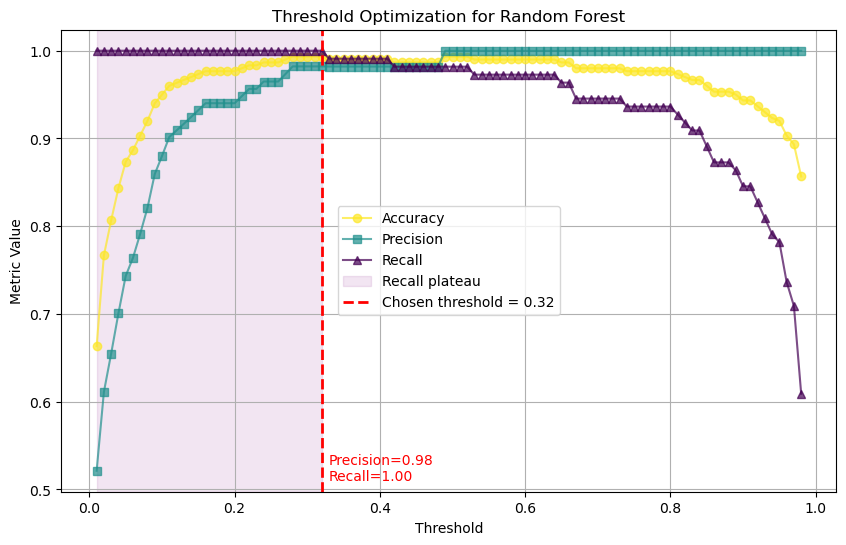

In [110]:
# Ajuster le seuil de décision
# Maximiser le rappel (pour éviter les faux négatifs) tout en maintenant la précision au plus haut niveau possible.

# calculer les métriques pour chaque seuil
y_proba = best_model_rf.predict_proba(X_test)[:, 1]  
thresholds = np.arange(0.01, 0.99, 0.01)

results = []

for t in thresholds:
    preds = (y_proba >= t).astype(int)
    results.append({
        'threshold': t,
        'accuracy': accuracy_score(y_test, preds),
        'precision': precision_score(y_test, preds),
        'recall': recall_score(y_test, preds)
    })

threshold_metrics = pd.DataFrame(results)


# plateau de recall 
max_recall = threshold_metrics['recall'].max()
plateau = threshold_metrics[threshold_metrics['recall'] == max_recall]

# plateau de precision dans le plateau de recall 
max_precision = plateau['precision'].max()
double_plateau = plateau[plateau['precision'] == max_precision]

# seils max 
best_row = double_plateau.loc[double_plateau['threshold'].idxmax()]
best_t_rf = best_row['threshold']

print("Best threshold:", best_t_rf)
print(best_row)


# Graphique des métriques en fonction du seuil
plt.figure(figsize=(10, 6))

cmap = plt.get_cmap("viridis_r")
colors = [cmap(x) for x in np.linspace(0, 1, 3)]


plt.plot(threshold_metrics['threshold'], threshold_metrics['accuracy'], 
         label='Accuracy', color=colors[0], marker='o', alpha=0.7)
plt.plot(threshold_metrics['threshold'], threshold_metrics['precision'], 
         label='Precision', color=colors[1], marker='s', alpha=0.7)
plt.plot(threshold_metrics['threshold'], threshold_metrics['recall'], 
         label='Recall', color=colors[2], marker='^', alpha=0.7)

# Le plateau
plt.axvspan(plateau['threshold'].min(), plateau['threshold'].max(), 
            color='purple', alpha=0.1, label='Recall plateau')

# Ligne verticale au seuil choisi
plt.axvline(best_t_rf, color='red', linestyle='--', linewidth=2, 
            label=f'Chosen threshold = {best_t_rf:.2f}')

plt.text(best_t_rf + 0.01, 0.51, 
         f"Precision={best_row['precision']:.2f}\nRecall={best_row['recall']:.2f}",
         color='red')

plt.xlabel('Threshold')
plt.ylabel('Metric Value')
plt.title('Threshold Optimization for Random Forest')
plt.legend()
plt.grid(True)
plt.savefig("Figures/fig_threshold_rf.jpeg",bbox_inches="tight")
plt.show()


4.4.5)
Afficher le modèle final, qui maximise le recall/rappel afin d'éviter les faux négatifs.

Threshold Random Forest : 0.32
Accuracy 0.993
Precision random forest : 0.982
Recall random forest : 1.000

Classification report pour le meilleur random forest:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       190
           1       0.98      1.00      0.99       110

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



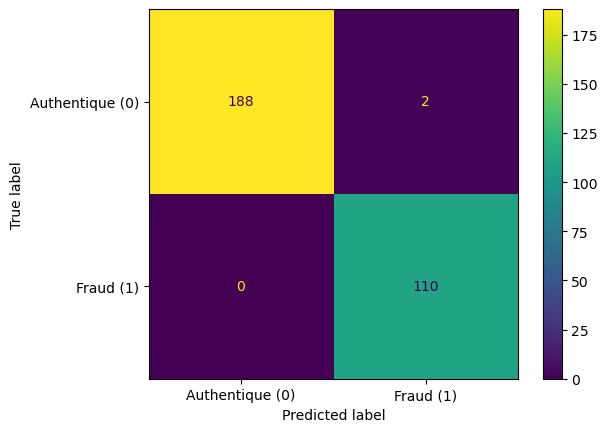

Text(0, 0.5, 'Taux de vrais positifs (TPR)')

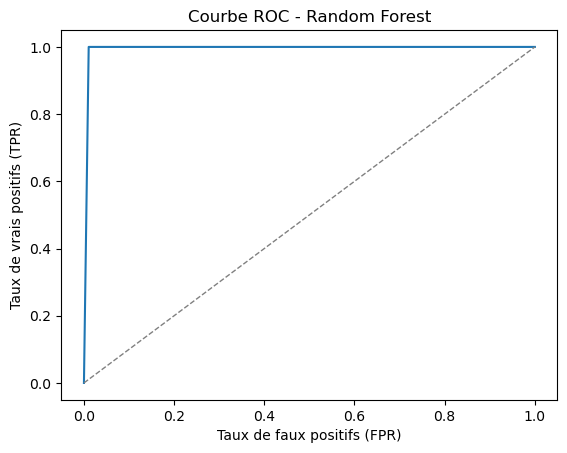

In [111]:
# Afficher le modèle final, qui maximise le recall/rappel afin d'éviter les faux négatifs.
# Le model final!
# Regression logistic avec meilleur seuil
# y_pred_thresh = y_logist_proba >= 0.1
y_preds_final = (y_proba >= best_t_rf).astype(int)

print('Threshold',model_name,":",best_t_rf)
print(f"Accuracy {accuracy_score(y_test, y_preds_final):.3f}")
print(f"Precision random forest : {precision_score(y_test, y_preds_final, pos_label=True):.3f}")
print(f"Recall random forest : {recall_score(y_test, y_preds_final, pos_label=True):.3f}")

print()
print("Classification report pour le meilleur random forest:")
print(classification_report(y_test, y_preds_final))

# Matrice de confusion
#print(f"Matrice de confusions regression logistique:\n", confusion_matrix(y_test, y_logist))
cm = confusion_matrix(y_test, y_preds_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Authentique (0)', 'Fraud (1)'])
disp.plot()
plt.savefig("Figures/fig_confusion_matrix_param_seuil_rf.jpeg",bbox_inches="tight")
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_preds_final)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
plt.title("Courbe ROC - Random Forest")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")


In [112]:
# Faire une Pipeline KNN
pipe_rf = make_pipeline(StandardScaler(),
                        RandomForestClassifier(random_state=42)
)

best_params_rf = {
    "randomforestclassifier__class_weight": "balanced",
    "randomforestclassifier__max_depth": 10,
    "randomforestclassifier__min_samples_split": 2,
    "randomforestclassifier__n_estimators": 100
}

pipe_rf.set_params(**best_params_rf)
pipe_rf.fit(X_train_raw, y_train_raw)


pipe_knn.set_params(**best_params_knn)
pipe_knn.fit(X_train_raw, y_train_raw)


,steps,"[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,13
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


In [113]:
# Souvgarder le model KNN avec joblib, et le X_train et y_train  
joblib.dump(pipe_rf,"Donnees_resultats/model_billet_fraud_rf.pkl")


['Donnees_resultats/model_billet_fraud_rf.pkl']

# 4.5) Neural network

<div style="border: 2px solid RGB(255,255,255);" >

4.5.1) Validation croisée

Identifier le meilleur modèle à l'aide du "roc_auc" validé par validation croisée


In [114]:
# Neural Network
# Cross validation des parametres

# Paramètres à prendre en compte et leur importance:
# hidden_layer_sizes : l'architecture de réseau neuronal. Plus de neurones → plus de capacité → risque de surapprentissage. / Plus de couches → plus de complexité → entraînement plus lent
# activation : Les neurones transforment leurs entrées. ... Parfois, la (tanh) fonctionne mieux sur de petits ensembles de données.
# alpha: L2 regularization (weight decay). Faible valeur d'alpha → régularisation faible → risque de surapprentissage / Valeur d'alpha élevée → régularisation forte → risque de sous-apprentissage

model_name = "Neural Network"
neural = MLPClassifier(max_iter=1000, random_state=42)

param_grid_nn = {  
    "hidden_layer_sizes": [(10,), (20,), (50,), (20,10)],
    "activation": ["relu", "tanh"],
    "alpha": [0.0001, 0.001, 0.01]
}

best_model_nn = run_grid_search_CV(neural, param_grid_nn, model_name)


Meilleur params Neural Network : {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (10,)}
Meilleur CV AUC pour Neural Network : 0.9988445710667933


4.5.2)
Afficher le "meilleur" model avec des parametres optimise

Neural Network
Accuracy 0.993
Precision neural network : 0.991
Recall neural network : 0.991

Classification report pour le meilleur neural network:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       190
           1       0.99      0.99      0.99       110

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



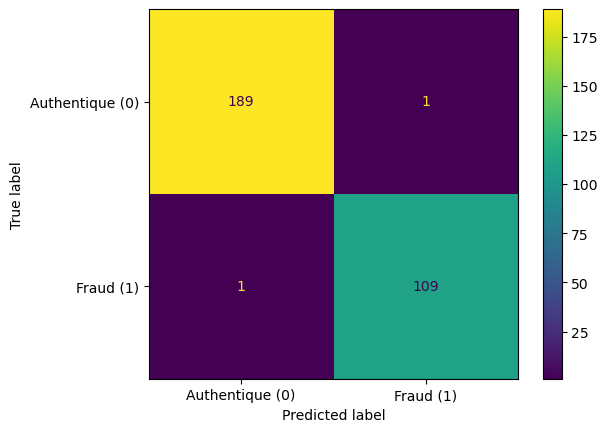

Text(0, 0.5, 'Taux de vrais positifs (TPR)')

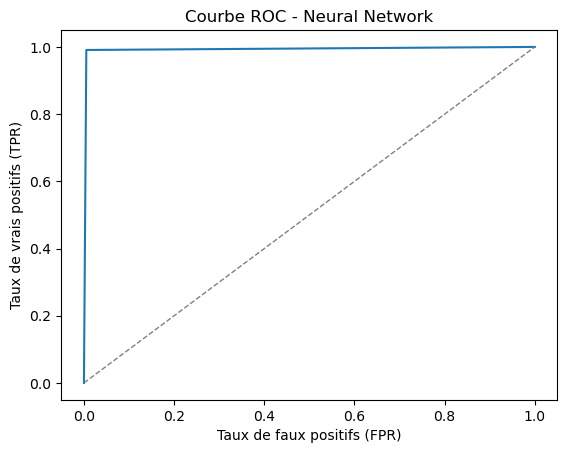

In [115]:
# Afficher le "meilleur" model avec des parametres optimise

# Meilleur model Neural Network avec parametres optimise avec ROC AUC
# Prédire les classes pour les données de test
y_nn = best_model_nn.predict(X_test)         

print(model_name)
print(f"Accuracy {accuracy_score(y_test, y_nn):.3f}")
print(f"Precision neural network : {precision_score(y_test,y_nn, pos_label=True):.3f}")
print(f"Recall neural network : {recall_score(y_test, y_nn, pos_label=True):.3f}")

print()
print("Classification report pour le meilleur neural network:")
print(classification_report(y_test, y_nn))

# Matrice de confusion
cm = confusion_matrix(y_test, y_nn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Authentique (0)', 'Fraud (1)'])
disp.plot()
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_nn)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
plt.title("Courbe ROC - Neural Network")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")


5.5.3) Comprendre la contribution des différentes variables/features à la prédiction du modèle

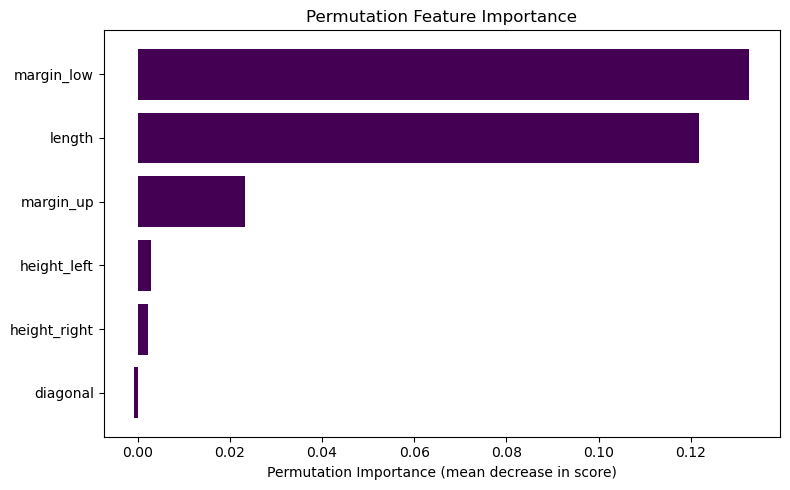

In [116]:

# Importance permutation

result = permutation_importance(
    best_model_nn, X_test, y_test,
    n_repeats=10,
    random_state=42
)

perm_importances = result.importances_mean
indices = np.argsort(perm_importances)

plt.figure(figsize=(8, 5))
plt.barh(range(len(perm_importances)), perm_importances[indices], color='#440154')
plt.yticks(range(len(perm_importances)), X.columns[indices])
plt.xlabel("Permutation Importance (mean decrease in score)")
plt.title("Permutation Feature Importance")
plt.tight_layout()
#plt.savefig("Figures/fig_feature_importance_nn.jpeg",bbox_inches="tight")
plt.show()


4.5.4)
Ajuster le seuil de décision

Best threshold: 0.14
threshold    0.140000
accuracy     0.980000
precision    0.948276
recall       1.000000
Name: 13, dtype: float64


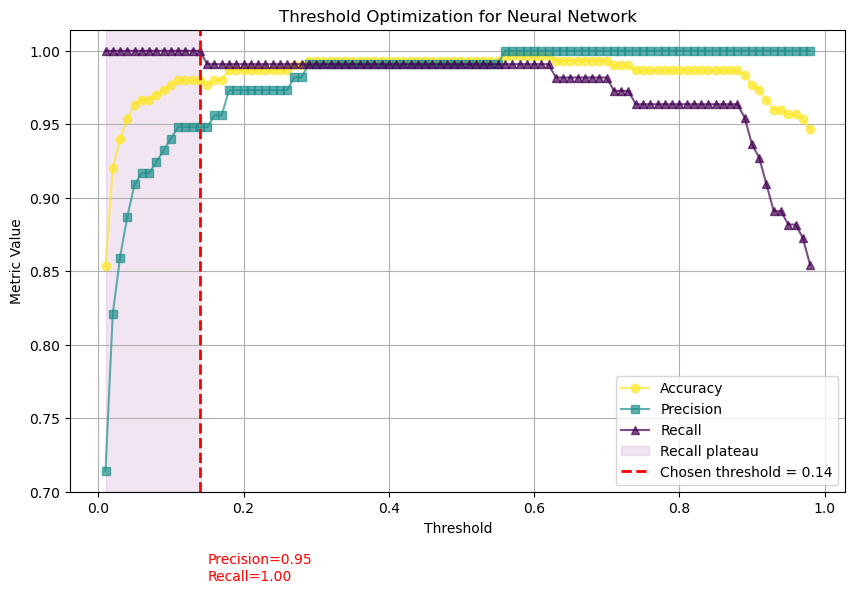

In [117]:
# Ajuster le seuil de décision
# Maximiser le rappel (pour éviter les faux négatifs) tout en maintenant la précision au plus haut niveau possible.

# calculer les métriques pour chaque seuil
y_proba = best_model_nn.predict_proba(X_test)[:, 1]  
thresholds = np.arange(0.01, 0.99, 0.01)

results = []

for t in thresholds:
    preds = (y_proba >= t).astype(int)
    results.append({
        'threshold': t,
        'accuracy': accuracy_score(y_test, preds),
        'precision': precision_score(y_test, preds),
        'recall': recall_score(y_test, preds)
    })



threshold_metrics = pd.DataFrame(results)

# plateau de recall 
max_recall = threshold_metrics['recall'].max()
plateau = threshold_metrics[threshold_metrics['recall'] == max_recall]

# plateau de precision dans le plateau de recall 
max_precision = plateau['precision'].max()
double_plateau = plateau[plateau['precision'] == max_precision]

# seils max 
best_row = double_plateau.loc[double_plateau['threshold'].idxmax()]
best_t_nn = best_row['threshold']

print("Best threshold:", best_t_nn)
print(best_row)

# Graphique des métriques en fonction du seuil
plt.figure(figsize=(10, 6))

cmap = plt.get_cmap("viridis_r")
colors = [cmap(x) for x in np.linspace(0, 1, 3)]


plt.plot(threshold_metrics['threshold'], threshold_metrics['accuracy'], 
         label='Accuracy', color=colors[0], marker='o', alpha=0.7)
plt.plot(threshold_metrics['threshold'], threshold_metrics['precision'], 
         label='Precision', color=colors[1], marker='s', alpha=0.7)
plt.plot(threshold_metrics['threshold'], threshold_metrics['recall'], 
         label='Recall', color=colors[2], marker='^', alpha=0.7)

# Le plateau
plt.axvspan(plateau['threshold'].min(), plateau['threshold'].max(), 
            color='purple', alpha=0.1, label='Recall plateau')

# Ligne verticale au seuil choisi
plt.axvline(best_t_nn, color='red', linestyle='--', linewidth=2, 
            label=f'Chosen threshold = {best_t_nn:.2f}')

plt.text(best_t_nn + 0.01, 0.64, 
         f"Precision={best_row['precision']:.2f}\nRecall={best_row['recall']:.2f}",
         color='red')

plt.xlabel('Threshold')
plt.ylabel('Metric Value')
plt.title('Threshold Optimization for Neural Network')
plt.legend()
plt.grid(True)
plt.show()

4.5.5)
Afficher le modèle final, qui maximise le recall/rappel afin d'éviter les faux négatifs.

Threshold Neural Network : 0.14
Accuracy 0.980
Precision neural network : 0.948
Recall neural network : 1.000

Classification report pour le meilleur neural network:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98       190
           1       0.95      1.00      0.97       110

    accuracy                           0.98       300
   macro avg       0.97      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300



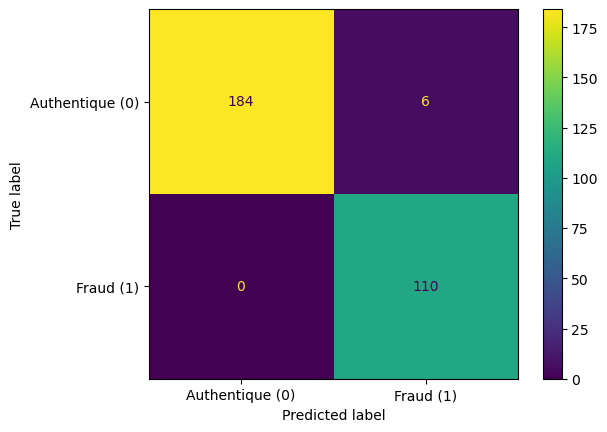

Text(0, 0.5, 'Taux de vrais positifs (TPR)')

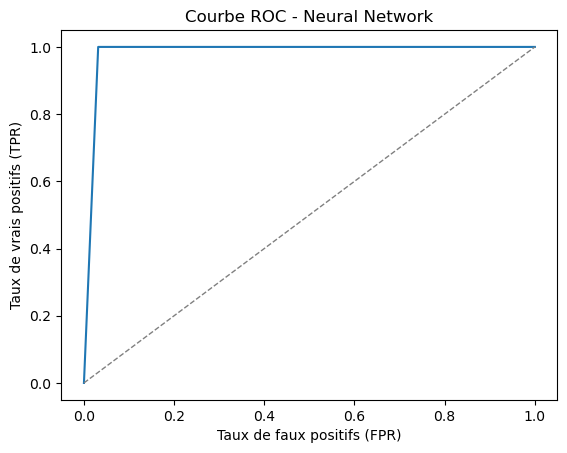

In [118]:
# Le model final!
# Neural network avec meilleur seuil
# y_pred_thresh = y_logist_proba >= 0.1
y_preds_final = (y_proba >= best_t_nn).astype(int)

print('Threshold',model_name,":",best_t_nn)
print(f"Accuracy {accuracy_score(y_test, y_preds_final):.3f}")
print(f"Precision neural network : {precision_score(y_test, y_preds_final, pos_label=True):.3f}")
print(f"Recall neural network : {recall_score(y_test, y_preds_final, pos_label=True):.3f}")

print()
print("Classification report pour le meilleur neural network:")
print(classification_report(y_test, y_preds_final))

# Matrice de confusion
#print(f"Matrice de confusions regression logistique:\n", confusion_matrix(y_test, y_logist))
cm = confusion_matrix(y_test, y_preds_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Authentique (0)', 'Fraud (1)'])
disp.plot()
plt.savefig("Figures/fig_confusion_matrix_param_seuil_nn.jpeg",bbox_inches="tight")
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, y_preds_final)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
plt.title("Courbe ROC - Neural Network")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")


# 5) Sélection du meilleur modèle


In [119]:
# Resume de resultats
results = {}

thresholds = {
    "Logistic Regression": best_t_lr,
    "KNN": best_t_knn,
    "Random Forest": best_t_rf,
    "Neural Net": best_t_nn
}

def evaluate_model(name, model, threshold):
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    results[name] = {
        "AUC": roc_auc_score(y_test, y_proba),
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Threshold": threshold
    }


evaluate_model("Logistic Regression", best_model_lr, thresholds["Logistic Regression"])
evaluate_model("KNN", best_model_knn, thresholds["KNN"])
evaluate_model("Random Forest", best_model_rf, thresholds["Random Forest"])
evaluate_model("Neural Net", best_model_nn, thresholds["Neural Net"])


pd.DataFrame(results).T

,AUC,Accuracy,F1,Recall,Precision,Threshold
Logistic Regression,0.999665,0.976667,0.969163,1.0,0.940171,0.31
KNN,0.999785,0.990000,0.986547,1.0,0.973451,0.15
Random Forest,0.999809,0.993333,0.990991,1.0,0.982143,0.32
Neural Net,0.999713,0.980000,0.973451,1.0,0.948276,0.14
